# Case Study: Analysing GDP in a Developing Country

Notebook Overview:
This notebook was prepared as part of a case study to demonstrate my **technical and analytical skills** in working with real-world, multi-source datasets. The objective is to explore key factors influencing GDP growth and standard of living, evaluate trade-offs with sustainability, and provide data-driven recommendations.

Please note that while I’ve made use of publicly available economic and social indicators (e.g., from the World Bank, UN, and OECD), **I am not a subject matter expert in macroeconomics or public policy**. The findings and recommendations presented are exploratory and for illustrative purposes only.

# I. Data Cleanup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
#folder_path = '/content/'                                                    # Colab
folder_path = '/Users/sunnyzheng/Desktop/Yulin Zheng - rbc Case Study/'       # Local

## Load Datasets

**GDP per Capita**

Source: WorldBank

URL: https://data.worldbank.org/indicator/NY.GDP.PCAP.CD

Description: "*GDP per capita is gross domestic product divided by midyear population. GDP is the sum of gross value added by all resident producers in the economy plus any product taxes and minus any subsidies not included in the value of the products. It is calculated without making deductions for depreciation of fabricated assets or for depletion and degradation of natural resources. Data are in current U.S. dollars.*"


In [3]:
GDP_per_capita = pd.read_csv(folder_path + 'GDP per capita (current US$).csv')
GDP_per_capita

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,27458.225331,27441.529662,28440.051964,30082.127645,31096.205074,22855.932320,27200.061079,30559.533535,33984.790620,NaN
1,Africa Eastern and Southern,AFE,GDP per capita (current US$),NY.GDP.PCAP.CD,186.132432,186.947182,197.408105,225.447007,209.005786,226.883067,...,1479.564123,1329.777824,1520.171298,1538.924188,1493.780445,1344.080962,1522.590088,1628.024526,1659.515290,NaN
2,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,565.569730,522.082216,525.469771,491.337221,496.602504,510.787063,356.496214,357.261153,415.707417,NaN
3,Africa Western and Central,AFW,GDP per capita (current US$),NY.GDP.PCAP.CD,121.938353,127.452629,133.825452,139.006714,148.547736,155.563837,...,1845.767804,1616.843198,1560.162999,1703.896392,1783.654365,1664.249176,1747.840549,1777.235012,1568.724310,NaN
4,Angola,AGO,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3213.902611,1807.952941,2437.259712,2538.591391,2189.855714,1449.922867,1925.874661,2929.694455,2308.159767,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3520.628507,3759.449591,4009.317993,4384.186241,4415.997161,4310.888247,5270.426702,5290.947472,5960.158205,NaN
262,"Yemen, Rep.",YEM,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1362.173794,975.359407,811.165964,633.887206,623.376165,559.564673,522.173513,615.702079,477.409029,NaN
263,South Africa,ZAF,GDP per capita (current US$),NY.GDP.PCAP.CD,532.147504,545.657512,563.423009,604.536855,645.873376,684.621228,...,6112.273825,5651.205852,6618.335083,6914.178032,6533.711210,5580.603831,6843.399419,6523.410978,6022.542542,NaN
264,Zambia,ZMB,GDP per capita (current US$),NY.GDP.PCAP.CD,221.559849,209.693206,202.281031,203.219451,229.979246,287.425476,...,1295.877887,1239.085279,1483.465773,1463.899979,1258.986198,951.644317,1127.160779,1447.123101,1330.727806,NaN


**Population**

Source: WorldBank

URL: https://data.worldbank.org/indicator/SP.POP.TOTL

Description: "*Total population is based on the de facto definition of population, which counts all residents regardless of legal status or citizenship. The values shown are midyear estimates.*"


In [4]:
population = pd.read_csv(folder_path + 'Population.csv')
population

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54922.0,55578.0,56320.0,57002.0,57619.0,58190.0,...,107906.0,108727.0,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0,NaN
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130072080.0,133534923.0,137171659.0,140945536.0,144904094.0,149033472.0,...,607123269.0,623369401.0,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750503764.0,NaN
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,9035043.0,9214083.0,9404406.0,9604487.0,9814318.0,10036008.0,...,33831764.0,34700612.0,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0,NaN
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,97630925.0,99706674.0,101854756.0,104089175.0,106388440.0,108772632.0,...,418127845.0,429454743.0,440882906.0,452195915.0,463365429.0,474569351.0,485920997.0,497387180.0,509398589.0,NaN
4,Angola,AGO,"Population, total",SP.POP.TOTL,5231654.0,5301583.0,5354310.0,5408320.0,5464187.0,5521981.0,...,28157798.0,29183070.0,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,"Population, total",SP.POP.TOTL,984846.0,1011421.0,1036950.0,1062737.0,1090270.0,1120168.0,...,1788274.0,1777568.0,1791019.0,1797086.0,1788891.0,1790152.0,1786080.0,1768096.0,1756366.0,NaN
262,"Yemen, Rep.",YEM,"Population, total",SP.POP.TOTL,5532301.0,5655232.0,5782221.0,5911135.0,6048006.0,6195593.0,...,31159379.0,32109010.0,33090921.0,34085182.0,35111408.0,36134863.0,37140230.0,38222876.0,39390799.0,NaN
263,South Africa,ZAF,"Population, total",SP.POP.TOTL,16440172.0,16908035.0,17418522.0,17954564.0,18511361.0,19089380.0,...,56723537.0,57259551.0,57635162.0,58613001.0,59587885.0,60562381.0,61502603.0,62378410.0,63212384.0,NaN
264,Zambia,ZMB,"Population, total",SP.POP.TOTL,3153729.0,3254086.0,3358099.0,3465907.0,3577017.0,3692086.0,...,16399089.0,16914423.0,17441320.0,17973569.0,18513839.0,19059395.0,19603607.0,20152938.0,20723965.0,NaN


**GDP Growth Rate**

Source: WorldBank

URL: https://data.worldbank.org/indicator/NY.GDP.MKTP.KD.ZG

Description: "*Annual percentage growth rate of GDP at market prices based on constant local currency. Aggregates are based on constant 2015 prices, expressed in U.S. dollars.*"


In [5]:
GDP_growrate = pd.read_csv(folder_path + 'GDP growth (annual %) .csv')
GDP_growrate

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.623626,1.719625,7.048533,2.397085,-2.232440,-26.211821,24.132627,8.517918,4.263719,NaN
1,Africa Eastern and Southern,AFE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,0.468736,7.869709,5.622374,4.690458,5.159574,...,3.004937,2.194761,2.684543,2.666632,2.194319,-2.864293,4.576393,3.553878,2.320138,NaN
2,Afghanistan,AFG,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,1.451315,2.260314,2.647003,1.189228,3.911603,-2.351101,-20.738839,-6.240172,2.710887,NaN
3,Africa Western and Central,AFW,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,1.873054,3.712777,7.111968,5.413943,4.120855,...,2.720365,0.160782,2.289810,2.844755,3.232903,-1.003994,4.037630,3.789680,3.354733,NaN
4,Angola,AGO,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,0.943572,-2.580050,-0.147213,-1.316362,-0.702273,-5.638215,1.199211,3.044727,1.001289,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,5.916231,5.571775,4.825656,3.406632,4.756801,-5.340275,10.745656,4.278499,4.067627,NaN
262,"Yemen, Rep.",YEM,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,-27.994546,-9.375124,-5.071796,0.752448,NaN,NaN,NaN,NaN,NaN,NaN
263,South Africa,ZAF,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,3.844734,6.177931,7.373709,7.939609,6.122798,...,1.321862,0.664552,1.157947,1.556784,0.259936,-6.168918,4.955033,1.911480,0.698485,NaN
264,Zambia,ZMB,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,1.361382,-2.490839,3.272393,12.214048,16.647456,...,2.920375,3.755100,3.525863,4.034494,1.441306,-2.785055,6.234922,5.211224,5.367943,NaN


**Government health expenditure**

Source: WorldBank

URL: https://data.worldbank.org/indicator/SH.XPD.CHEX.GD.ZS

Description: "*Level of current health expenditure expressed as a percentage of GDP. Estimates of current health expenditures include healthcare goods and services consumed during each year.*"

In [6]:
health_expenditure = pd.read_csv(folder_path + 'Current health expenditure (% of GDP).csv')
health_expenditure

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,5.971352,6.067770,5.928989,5.789177,5.812624,6.035792,6.043925,5.728123,NaN,NaN
2,Afghanistan,AFG,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,10.105348,11.818590,12.620817,14.208419,14.831320,15.533614,21.508461,23.088169,NaN,NaN
3,Africa Western and Central,AFW,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,3.870586,3.835177,3.744485,3.302830,3.326789,3.891477,4.154973,4.210206,NaN,NaN
4,Angola,AGO,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.605795,2.713150,2.793838,2.594822,2.475188,3.274885,3.092771,2.927376,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,"Yemen, Rep.",YEM,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.252857,4.845067,4.847699,5.272018,5.838126,5.772708,6.175427,6.186667,NaN,NaN
263,South Africa,ZAF,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,8.053042,8.079594,7.977112,8.081965,8.246526,9.013292,8.674328,8.770866,NaN,NaN
264,Zambia,ZMB,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.429743,4.469232,4.781562,4.769967,6.753303,6.306744,6.639514,5.255923,NaN,NaN


**Life Expectancy**

Source: Our World in Data

URL: https://ourworldindata.org/life-expectancy#all-charts

Description: "*Period life expectancy is a metric that summarizes death rates across all age groups in one particular year. It represents the average expected lifespan of a hypothetical population for the remainder of their lives.*"

In [7]:
life_expectancy = pd.read_csv(folder_path + 'life-expectancy.csv')
life_expectancy

,Entity,Code,Year,Period life expectancy at birth - Sex: total - Age: 0
0,Afghanistan,AFG,1950,28.1563
1,Afghanistan,AFG,1951,28.5836
2,Afghanistan,AFG,1952,29.0138
3,Afghanistan,AFG,1953,29.4521
4,Afghanistan,AFG,1954,29.6975
...,...,...,...,...
21560,Zimbabwe,ZWE,2019,61.0603
21561,Zimbabwe,ZWE,2020,61.5300
21562,Zimbabwe,ZWE,2021,60.1347
21563,Zimbabwe,ZWE,2022,62.3601


**infant_mortality rate per 1000 live birth**

Source: WorldBank

URL: https://data.worldbank.org/indicator/SP.DYN.IMRT.IN

Description: "*Infant mortality rate is the number of infants dying before reaching one year of age, per 1,000 live births in a given year.*"

In [8]:
infant_mortality = pd.read_csv(folder_path + 'Mortality rate, infant (per 1,000 live births).csv')
infant_mortality

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,"Mortality rate, infant (per 1,000 live births)",SP.DYN.IMRT.IN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Mortality rate, infant (per 1,000 live births)",SP.DYN.IMRT.IN,NaN,NaN,NaN,NaN,NaN,NaN,...,49.010305,47.773920,46.783264,43.851814,42.190074,41.125853,40.087560,39.673059,37.919755,NaN
2,Afghanistan,AFG,"Mortality rate, infant (per 1,000 live births)",SP.DYN.IMRT.IN,251.2,248.4,245.4,242.5,239.7,236.9,...,64.200000,62.300000,60.400000,58.600000,56.900000,55.300000,53.600000,52.000000,50.400000,NaN
3,Africa Western and Central,AFW,"Mortality rate, infant (per 1,000 live births)",SP.DYN.IMRT.IN,NaN,NaN,NaN,NaN,NaN,NaN,...,63.449505,62.430649,61.502277,60.121948,59.567703,57.550208,56.474044,56.430320,53.337216,NaN
4,Angola,AGO,"Mortality rate, infant (per 1,000 live births)",SP.DYN.IMRT.IN,NaN,NaN,NaN,NaN,NaN,NaN,...,51.100000,48.900000,47.000000,45.300000,43.800000,42.300000,40.900000,39.600000,38.300000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,"Mortality rate, infant (per 1,000 live births)",SP.DYN.IMRT.IN,NaN,NaN,NaN,NaN,NaN,NaN,...,13.000000,12.300000,11.500000,10.800000,10.200000,9.600000,9.100000,8.700000,8.300000,NaN
262,"Yemen, Rep.",YEM,"Mortality rate, infant (per 1,000 live births)",SP.DYN.IMRT.IN,272.8,270.4,267.9,264.8,261.1,256.6,...,41.300000,40.500000,39.700000,39.600000,38.800000,37.400000,36.700000,35.700000,34.700000,NaN
263,South Africa,ZAF,"Mortality rate, infant (per 1,000 live births)",SP.DYN.IMRT.IN,NaN,NaN,NaN,NaN,NaN,NaN,...,29.700000,28.400000,27.300000,26.300000,25.600000,25.000000,24.700000,24.500000,24.400000,NaN
264,Zambia,ZMB,"Mortality rate, infant (per 1,000 live births)",SP.DYN.IMRT.IN,99.1,97.9,96.8,95.7,95.0,94.5,...,42.500000,40.900000,38.800000,37.500000,35.700000,34.500000,33.400000,32.200000,30.900000,NaN


**Health Coverage**

Source: Our World in Data

URL: https://ourworldindata.org/grapher/health-coverage-vs-gdp-per-capita-simple

Description: "*Percentage of population covered by health insurance (including population having free access to healthcare services provided by the State). GDP per capita is adjusted for inflation and for differences in living costs between countries.*"

In [9]:
health_coverage = pd.read_csv(folder_path + 'health-protection-coverage.csv')
health_coverage

,Entity,Code,Year,Share of population covered by health insurance (ILO (2014))
0,Albania,ALB,2008,23.6
1,Algeria,DZA,2005,85.2
2,American Samoa,ASM,2009,3.0
3,Angola,AGO,2010,0.0
4,Antigua and Barbuda,ATG,2007,51.1
...,...,...,...,...
157,Venezuela,VEN,2010,100.0
158,Vietnam,VNM,2010,61.0
159,Yemen,YEM,2003,42.0
160,Zambia,ZMB,2008,8.4


**hospital beds avaliablity per 1000 people**

Source: Our World in Data

URL: https://ourworldindata.org/grapher/hospital-beds-per-1000-people?tab=chart

Description: "*Hospital beds include inpatient beds available in public, private, general, and specialized hospitals and rehabilitation centers. In most cases beds for both acute and chronic care are included.*"

In [10]:
hospital_bedsavaliablity = pd.read_csv(folder_path + 'Hospital beds per 1,000 people.csv')
hospital_bedsavaliablity

,Entity,Code,Year,"Hospital beds (per 1,000 people)"
0,Afghanistan,AFG,1960,0.170627
1,Afghanistan,AFG,1970,0.199000
2,Afghanistan,AFG,1981,0.275600
3,Afghanistan,AFG,1987,0.309100
4,Afghanistan,AFG,1990,0.249800
...,...,...,...,...
5120,Zimbabwe,ZWE,2009,1.880000
5121,Zimbabwe,ZWE,2010,1.850000
5122,Zimbabwe,ZWE,2011,1.820000
5123,Zimbabwe,ZWE,2012,1.940000


**school enrollment rate**

Source: Our World in Data

URL: https://ourworldindata.org/grapher/gross-enrollment-ratio-in-tertiary-education?tab=table&time=2000..latest

Description: "*Number of people of any age group who are enrolled in tertiary education expressed as a percentage of the total population of the five-year age group following on from secondary school leaving.*"

In [11]:
school_enrollment_rate = pd.read_csv(folder_path + 'enrollment-ratio-in-tertiary-education.csv')
school_enrollment_rate

,Entity,Code,Year,Gross enrolment ratio in tertiary education
0,Afghanistan,AFG,1970,0.769560
1,Afghanistan,AFG,1971,0.928270
2,Afghanistan,AFG,1972,0.959540
3,Afghanistan,AFG,1973,1.104440
4,Afghanistan,AFG,1974,1.031920
...,...,...,...,...
7922,Zimbabwe,ZWE,2016,8.587643
7923,Zimbabwe,ZWE,2017,9.500181
7924,Zimbabwe,ZWE,2018,9.427848
7925,Zimbabwe,ZWE,2019,11.130139


**Government expenditure on education, total (% of GDP)**

Source: WorldBank

URL: https://data.worldbank.org/indicator/SE.XPD.TOTL.GD.ZS

Description: "*General government expenditure on education (current, capital, and transfers) is expressed as a percentage of GDP. It includes expenditure funded by transfers from international sources to government. General government usually refers to local, regional and central governments.*"

In [12]:
edu_expediture = pd.read_csv(folder_path + 'Education spending as share total government spending.csv')
edu_expediture

,Entity,Code,Year,"Government expenditure on education, total (% of government expenditure)"
0,Afghanistan,AFG,2006,14.559212
1,Afghanistan,AFG,2007,10.814692
2,Afghanistan,AFG,2008,4.860586
3,Afghanistan,AFG,2009,6.492490
4,Afghanistan,AFG,2010,6.395580
...,...,...,...,...
3957,Zimbabwe,ZWE,2016,23.527084
3958,Zimbabwe,ZWE,2017,19.691229
3959,Zimbabwe,ZWE,2018,19.158785
3960,Zimbabwe,ZWE,2019,10.463589


**literacy rate**

Source: Our World in Data

URL: https://ourworldindata.org/grapher/cross-country-literacy-rates?tab=table&country=East+Asia+%26+Pacific~Sub-Saharan+Africa~Europe+%26+Central+Asia~Latin+America+%26+Caribbean~Middle+East+%26+North+Africa~South+Asia

Description: "*Share of the population aged 15 and above who can read and write a short, simple statement on their everyday life.*"

In [13]:
literacy_rate =  pd.read_csv(folder_path + 'cross-country-literacy-rates.csv')
literacy_rate

,Entity,Code,Year,Literacy rate (historical and recent)
0,Afghanistan,AFG,1979,18.00000
1,Afghanistan,AFG,2011,31.00000
2,Afghanistan,AFG,2015,33.75384
3,Afghanistan,AFG,2021,37.00000
4,Albania,ALB,2001,99.00000
...,...,...,...,...
2435,Zimbabwe,ZWE,1982,78.00000
2436,Zimbabwe,ZWE,1992,84.00000
2437,Zimbabwe,ZWE,2011,83.58271
2438,Zimbabwe,ZWE,2015,86.87348


**Carbon dioxide (CO2) emissions (total) excluding LULUCF (Mt CO2e)**

Source: WorldBank

URL: https://data.worldbank.org/indicator/EN.GHG.CO2.MT.CE.AR5

Description: "*A measure of annual emissions of carbon dioxide (CO2), one of the six Kyoto greenhouse gases (GHG), from the agriculture, energy, waste, and industrial sectors, excluding LULUCF. The measure is standardized to carbon dioxide equivalent values using the Global Warming Potential (GWP) factors of IPCC's 5th Assessment Report (AR5).*"

In [14]:
CO2_emission = pd.read_csv(folder_path + 'Carbon dioxide (CO2) emissions (total) excluding LULUCF (Mt CO2e).csv')
CO2_emission

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,NaN,NaN,NaN,NaN,NaN,NaN,...,0.4620,0.4849,0.4666,0.4659,0.5579,0.4526,0.5006,0.5027,0.5300,NaN
1,Africa Eastern and Southern,AFE,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,NaN,NaN,NaN,NaN,NaN,NaN,...,621.8665,628.5365,637.9068,645.8367,654.5401,578.0520,606.3945,588.4335,579.8655,NaN
2,Afghanistan,AFG,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,NaN,NaN,NaN,NaN,NaN,NaN,...,8.3465,7.5276,8.0661,7.9320,7.2491,7.0541,7.9308,8.2599,8.7073,NaN
3,Africa Western and Central,AFW,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,NaN,NaN,NaN,NaN,NaN,NaN,...,208.8912,217.4430,218.2637,230.4901,240.4359,235.9365,249.1554,251.4104,245.6408,NaN
4,Angola,AGO,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,NaN,NaN,NaN,NaN,NaN,NaN,...,33.0975,31.2858,27.9421,26.2589,27.5732,20.7109,25.2628,27.3530,28.2299,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,"Yemen, Rep.",YEM,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,NaN,NaN,NaN,NaN,NaN,NaN,...,14.2508,10.6288,10.3922,12.1543,12.4646,11.5039,11.5483,11.1906,10.8988,NaN
263,South Africa,ZAF,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,NaN,NaN,NaN,NaN,NaN,NaN,...,460.0515,460.4962,469.8115,473.6998,478.5884,418.7732,428.5332,409.4074,397.3730,NaN
264,Zambia,ZMB,Carbon dioxide (CO2) emissions (total) excludi...,EN.GHG.CO2.MT.CE.AR5,NaN,NaN,NaN,NaN,NaN,NaN,...,5.3200,5.8030,7.0772,8.0562,7.0267,7.4772,7.7646,7.8070,8.0590,NaN


**Individuals using the Internet (% of population)**

Source: WorldBank

URL: https://data.worldbank.org/indicator/IT.NET.USER.ZS

Description: "*Internet users are individuals who have used the Internet (from any location) in the last 3 months. The Internet can be used via a computer, mobile phone, personal digital assistant, games machine, digital TV etc.*"

In [15]:
internet_coverage = pd.read_csv(folder_path + 'Individuals using the Internet (% of population).csv')
internet_coverage

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,88.70,93.5,97.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,8.26,11.0,13.5,16.8,17.6,17.0,16.5,17.2,17.7,NaN
3,Africa Western and Central,AFW,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,22.00,23.2,26.0,29.0,32.1,36.6,39.4,42.1,44.8,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,83.9,89.4,NaN,NaN,NaN,NaN,NaN,NaN
262,"Yemen, Rep.",YEM,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,24.10,24.6,26.7,NaN,NaN,13.8,NaN,NaN,NaN,NaN
263,South Africa,ZAF,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,51.90,54.0,56.2,62.4,69.7,72.1,75.0,75.5,75.7,NaN
264,Zambia,ZMB,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,8.80,10.3,12.2,14.3,18.7,24.5,32.5,32.0,33.0,NaN


**Employment to population ratio, 15+, total (%)**

Source: WorldBank

URL: https://databank.worldbank.org/metadataglossary/world-development-indicators/series/SL.EMP.TOTL.SP.ZS

Description: "*Employment to population ratio is the proportion of a country's population that is employed. Employment is defined as persons of working age who, during a short reference period, were engaged in any activity to produce goods or provide services for pay or profit, whether at work during the reference period (i.e. who worked in a job for at least one hour) or not at work due to temporary absence from a job, or to working-time arrangements. Ages 15 and older are generally considered the working-age population.*"

In [16]:
employment_rate = pd.read_csv(folder_path + 'Employment to population ratio, 15+, total (%) (modeled ILO estimate).csv')
employment_rate

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,"Employment to population ratio, 15+, total (%)...",SL.EMP.TOTL.SP.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Employment to population ratio, 15+, total (%)...",SL.EMP.TOTL.SP.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,64.723023,64.163906,63.467813,63.076943,62.608660,60.860772,61.066115,61.656779,63.896686,63.804891
2,Afghanistan,AFG,"Employment to population ratio, 15+, total (%)...",SL.EMP.TOTL.SP.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,42.896000,42.449000,42.014000,40.468000,38.922000,36.710000,36.022000,32.333000,32.402000,32.511000
3,Africa Western and Central,AFW,"Employment to population ratio, 15+, total (%)...",SL.EMP.TOTL.SP.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,69.261143,69.214771,68.691646,68.439693,68.194445,67.367380,67.548895,68.324007,69.075871,68.988629
4,Angola,AGO,"Employment to population ratio, 15+, total (%)...",SL.EMP.TOTL.SP.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,63.624000,63.319000,63.050000,62.818000,62.645000,62.257000,64.306000,64.573000,64.739000,64.753000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,"Employment to population ratio, 15+, total (%)...",SL.EMP.TOTL.SP.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,"Yemen, Rep.",YEM,"Employment to population ratio, 15+, total (%)...",SL.EMP.TOTL.SP.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,26.328000,26.345000,26.442000,26.892000,27.114000,26.670000,26.479000,27.185000,27.327000,27.235000
263,South Africa,ZAF,"Employment to population ratio, 15+, total (%)...",SL.EMP.TOTL.SP.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,43.184000,42.583000,42.885000,42.490000,41.722000,38.719000,36.798000,37.999000,39.742000,39.116000
264,Zambia,ZMB,"Employment to population ratio, 15+, total (%)...",SL.EMP.TOTL.SP.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,55.349000,55.655000,55.955000,55.538000,56.239000,57.200000,56.993000,55.963000,55.910000,55.821000


**Unemployment, total (% of total labor force)**

Source: WorldBank

URL: https://data.worldbank.org/indicator/SL.UEM.TOTL.ZS

Description: "*Unemployment refers to the share of the labor force that is without work but available for and seeking employment.*"

In [17]:
unemployment_rate = pd.read_csv(folder_path + 'Unemployment rate.csv')
unemployment_rate

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,7.036357,7.194666,7.346331,7.360513,7.584419,8.191395,8.577385,7.985202,7.806365,7.772656
2,Afghanistan,AFG,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,9.052000,10.133000,11.184000,11.196000,11.185000,11.710000,11.994000,14.100000,13.991000,13.295000
3,Africa Western and Central,AFW,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.164467,4.157574,4.274196,4.323631,4.395271,4.852393,4.736732,3.658573,3.277245,3.218313
4,Angola,AGO,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,16.490000,16.575000,16.610000,16.594000,16.497000,16.690000,15.799000,14.602000,14.537000,14.464000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,"Yemen, Rep.",YEM,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,17.900000,18.416000,18.603000,17.584000,17.202000,17.953000,18.287000,17.363000,17.091000,17.086000
263,South Africa,ZAF,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,25.149000,26.536000,27.035000,26.906000,28.468000,29.217000,34.007000,33.268000,32.098000,33.168000
264,Zambia,ZMB,"Unemployment, total (% of total labor force) (...",SL.UEM.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,5.942000,5.239000,4.529000,5.033000,5.542000,6.033000,5.199000,5.995000,5.905000,5.961000


**Foreign direct investment, net inflows (BoP, current US$)**

Source: WorldBank

URL: https://data.worldbank.org/indicator/BX.KLT.DINV.CD.WD

Description: "*Foreign direct investment refers to direct investment equity flows in the reporting economy. It is the sum of equity capital, reinvestment of earnings, and other capital. Direct investment is a category of cross-border investment associated with a resident in one economy having control or a significant degree of influence on the management of an enterprise that is resident in another economy.*"

In [18]:
foreign_invest = pd.read_csv(folder_path + 'Foreign direct investment, net inflows (BoP, current US$).csv')
foreign_invest

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,"Foreign direct investment, net inflows (BoP, c...",BX.KLT.DINV.CD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.688140e+07,2.755083e+07,1.624568e+08,1.441463e+08,-7.522654e+07,1.610670e+08,1.335451e+08,2.481503e+08,-1.374594e+08,NaN
1,Africa Eastern and Southern,AFE,"Foreign direct investment, net inflows (BoP, c...",BX.KLT.DINV.CD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,2.863867e+10,1.666027e+10,1.032898e+10,1.359466e+10,1.492729e+10,1.322101e+10,5.435770e+10,2.116323e+10,2.140412e+10,NaN
2,Afghanistan,AFG,"Foreign direct investment, net inflows (BoP, c...",BX.KLT.DINV.CD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.691466e+08,9.359132e+07,5.153390e+07,1.194351e+08,2.340455e+07,1.297015e+07,2.060098e+07,NaN,NaN,NaN
3,Africa Western and Central,AFW,"Foreign direct investment, net inflows (BoP, c...",BX.KLT.DINV.CD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.659755e+10,1.564812e+10,1.774243e+10,1.495230e+10,1.282186e+10,1.098518e+10,1.701413e+10,1.660132e+10,1.922561e+10,NaN
4,Angola,AGO,"Foreign direct investment, net inflows (BoP, c...",BX.KLT.DINV.CD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.002822e+10,-1.795176e+08,-7.397295e+09,-6.456076e+09,-4.098479e+09,-1.866468e+09,-4.355117e+09,-6.598653e+09,-2.119632e+09,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,"Foreign direct investment, net inflows (BoP, c...",BX.KLT.DINV.CD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,3.433506e+08,2.437871e+08,2.868352e+08,3.185430e+08,2.850816e+08,3.946253e+08,5.009279e+08,7.641623e+08,9.086585e+08,NaN
262,"Yemen, Rep.",YEM,"Foreign direct investment, net inflows (BoP, c...",BX.KLT.DINV.CD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.544481e+07,-5.610000e+08,-2.698500e+08,-2.820983e+08,-3.709828e+08,NaN,NaN,NaN,NaN,NaN
263,South Africa,ZAF,"Foreign direct investment, net inflows (BoP, c...",BX.KLT.DINV.CD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.521140e+09,2.215307e+09,2.058580e+09,5.569462e+09,5.116098e+09,3.153553e+09,4.065879e+10,9.238991e+09,3.442332e+09,NaN
264,Zambia,ZMB,"Foreign direct investment, net inflows (BoP, c...",BX.KLT.DINV.CD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.582667e+09,6.628139e+08,1.107520e+09,4.084385e+08,5.479679e+08,2.452055e+08,3.942174e+08,-6.511886e+07,8.590733e+07,NaN


**External balance on goods and services (% of GDP)**

Source: WorldBank

URL: https://data.worldbank.org/indicator/NE.RSB.GNFS.ZS

Description: "*External balance on goods and services (formerly resource balance) equals exports of goods and services minus imports of goods and services (previously nonfactor services).*"

In [19]:
goods_services_external_balance = pd.read_csv(folder_path + 'External balance on goods and services as a percent of GDP.csv')
goods_services_external_balance

,Entity,Code,Year,External balance on goods and services (% of GDP)
0,Afghanistan,AFG,2020,-25.868260
1,Afghanistan,AFG,2021,-22.727411
2,Afghanistan,AFG,2022,-36.125385
3,Afghanistan,AFG,2023,-33.723072
4,Albania,ALB,1980,0.420891
...,...,...,...,...
9528,Zimbabwe,ZWE,2019,-0.687648
9529,Zimbabwe,ZWE,2020,-2.727239
9530,Zimbabwe,ZWE,2021,-5.296647
9531,Zimbabwe,ZWE,2022,-9.019267


## Reformat

We start at formatting the datasets into the same format -> years are all in rows instead of columns. Also apply filters to only keep focus on recent years (2000 - 2023).

In [20]:
# we start at GDP_per_capita
GDP_per_capita = GDP_per_capita.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='GDP per capital (US$)'
)

# Convert year to integer
GDP_per_capita['Year'] = GDP_per_capita['Year'].astype(int)
GDP_per_capita

,Country Name,Country Code,Year,GDP per capital (US$)
0,Aruba,ABW,2000,20681.023027
1,Africa Eastern and Southern,AFE,2000,707.120376
2,Afghanistan,AFG,2000,174.930991
3,Africa Western and Central,AFW,2000,516.932316
4,Angola,AGO,2000,563.733796
...,...,...,...,...
6379,Kosovo,XKX,2023,5960.158205
6380,"Yemen, Rep.",YEM,2023,477.409029
6381,South Africa,ZAF,2023,6022.542542
6382,Zambia,ZMB,2023,1330.727806


In [21]:
population = population.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='Total Population'
)

# Convert year to integer
population['Year'] = population['Year'].astype(int)

population

,Country Name,Country Code,Year,Total Population
0,Aruba,ABW,2000,90588.0
1,Africa Eastern and Southern,AFE,2000,406156661.0
2,Afghanistan,AFG,2000,20130327.0
3,Africa Western and Central,AFW,2000,274968446.0
4,Angola,AGO,2000,16194869.0
...,...,...,...,...
6379,Kosovo,XKX,2023,1756366.0
6380,"Yemen, Rep.",YEM,2023,39390799.0
6381,South Africa,ZAF,2023,63212384.0
6382,Zambia,ZMB,2023,20723965.0


In [22]:
GDP_growrate = GDP_growrate.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='GDP Growth (%)'
)

# Convert year to integer
GDP_growrate['Year'] = GDP_growrate['Year'].astype(int)

GDP_growrate


,Country Name,Country Code,Year,GDP Growth (%)
0,Aruba,ABW,2000,7.622921
1,Africa Eastern and Southern,AFE,2000,3.214946
2,Afghanistan,AFG,2000,NaN
3,Africa Western and Central,AFW,2000,3.868479
4,Angola,AGO,2000,3.054624
...,...,...,...,...
6379,Kosovo,XKX,2023,4.067627
6380,"Yemen, Rep.",YEM,2023,NaN
6381,South Africa,ZAF,2023,0.698485
6382,Zambia,ZMB,2023,5.367943


In [23]:
# now we do the same for health expenditure to long format
health_expenditure = health_expenditure.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='Health Expenditure (% of GDP)'
)

# Convert year to integer
health_expenditure['Year'] = health_expenditure['Year'].astype(int)

health_expenditure

,Country Name,Country Code,Year,Health Expenditure (% of GDP)
0,Aruba,ABW,2000,NaN
1,Africa Eastern and Southern,AFE,2000,5.654027
2,Afghanistan,AFG,2000,NaN
3,Africa Western and Central,AFW,2000,3.462852
4,Angola,AGO,2000,1.908599
...,...,...,...,...
6379,Kosovo,XKX,2023,NaN
6380,"Yemen, Rep.",YEM,2023,NaN
6381,South Africa,ZAF,2023,NaN
6382,Zambia,ZMB,2023,NaN


In [24]:
# we then rename the life_expectancy columns names to match with others and filter the years into needed
life_expectancy.rename(columns={'Entity': 'Country Name'}, inplace=True)
life_expectancy.rename(columns={'Code': 'Country Code'}, inplace=True)
life_expectancy.columns = life_expectancy.columns.str.strip()
life_expectancy.rename(columns={
    'Period life expectancy at birth - Sex: total - Age: 0': 'Expected_Age'
}, inplace=True)

life_expectancy = life_expectancy[(life_expectancy['Year'] >= 2000) & (life_expectancy['Year'] < 2024)]

life_expectancy

,Country Name,Country Code,Year,Expected_Age
50,Afghanistan,AFG,2000,55.0047
51,Afghanistan,AFG,2001,55.5113
52,Afghanistan,AFG,2002,56.2251
53,Afghanistan,AFG,2003,57.1713
54,Afghanistan,AFG,2004,57.8098
...,...,...,...,...
21560,Zimbabwe,ZWE,2019,61.0603
21561,Zimbabwe,ZWE,2020,61.5300
21562,Zimbabwe,ZWE,2021,60.1347
21563,Zimbabwe,ZWE,2022,62.3601


In [25]:
# same to health_coverage
health_coverage.rename(columns={'Entity': 'Country Name'}, inplace=True)
health_coverage.rename(columns={'Code': 'Country Code'}, inplace=True)
health_coverage.columns = health_coverage.columns.str.strip()

health_coverage

,Country Name,Country Code,Year,Share of population covered by health insurance (ILO (2014))
0,Albania,ALB,2008,23.6
1,Algeria,DZA,2005,85.2
2,American Samoa,ASM,2009,3.0
3,Angola,AGO,2010,0.0
4,Antigua and Barbuda,ATG,2007,51.1
...,...,...,...,...
157,Venezuela,VEN,2010,100.0
158,Vietnam,VNM,2010,61.0
159,Yemen,YEM,2003,42.0
160,Zambia,ZMB,2008,8.4


In [26]:
# # now we do the same for infant_mortality to long format
infant_mortality = infant_mortality.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='Infant Mortality Rate (per 1,000)'
)

# Convert Year to int
infant_mortality['Year'] = infant_mortality['Year'].astype(int)
infant_mortality

,Country Name,Country Code,Year,"Infant Mortality Rate (per 1,000)"
0,Aruba,ABW,2000,NaN
1,Africa Eastern and Southern,AFE,2000,85.202739
2,Afghanistan,AFG,2000,110.100000
3,Africa Western and Central,AFW,2000,93.006571
4,Angola,AGO,2000,115.000000
...,...,...,...,...
6379,Kosovo,XKX,2023,8.300000
6380,"Yemen, Rep.",YEM,2023,34.700000
6381,South Africa,ZAF,2023,24.400000
6382,Zambia,ZMB,2023,30.900000


In [27]:
# now we do the same for hospital_bedsavaliablity to limit the years and reformate th ecolumn names
hospital_bedsavaliablity.rename(columns={'Entity': 'Country Name'}, inplace=True)
hospital_bedsavaliablity.rename(columns={'Code': 'Country Code'}, inplace=True)
hospital_bedsavaliablity.columns = hospital_bedsavaliablity.columns.str.strip()

hospital_bedsavaliablity = hospital_bedsavaliablity[(hospital_bedsavaliablity['Year'] >= 2000) & (hospital_bedsavaliablity['Year'] < 2024)]
hospital_bedsavaliablity

,Country Name,Country Code,Year,"Hospital beds (per 1,000 people)"
5,Afghanistan,AFG,2000,0.30
6,Afghanistan,AFG,2001,0.39
7,Afghanistan,AFG,2002,0.39
8,Afghanistan,AFG,2003,0.39
9,Afghanistan,AFG,2004,0.39
...,...,...,...,...
5120,Zimbabwe,ZWE,2009,1.88
5121,Zimbabwe,ZWE,2010,1.85
5122,Zimbabwe,ZWE,2011,1.82
5123,Zimbabwe,ZWE,2012,1.94


In [28]:
# for school_enrollment_rate, we reformat the year columns in to rows and limit the year range
school_enrollment_rate.rename(columns={
    'Entity': 'Country Name',
    'Code': 'Country Code',
    'Gross enrolment ratio in tertiary education': 'tertiary_edu_enroll_rate'
}, inplace=True)


#Strip whitespace
school_enrollment_rate.columns = school_enrollment_rate.columns.str.strip()

school_enrollment_rate = school_enrollment_rate[(school_enrollment_rate['Year'] >= 2000) & (school_enrollment_rate['Year'] < 2024)]
school_enrollment_rate

,Country Name,Country Code,Year,tertiary_edu_enroll_rate
14,Afghanistan,AFG,2003,1.374350
15,Afghanistan,AFG,2004,1.390640
16,Afghanistan,AFG,2009,3.938160
17,Afghanistan,AFG,2011,3.686860
18,Afghanistan,AFG,2014,8.397640
...,...,...,...,...
7922,Zimbabwe,ZWE,2016,8.587643
7923,Zimbabwe,ZWE,2017,9.500181
7924,Zimbabwe,ZWE,2018,9.427848
7925,Zimbabwe,ZWE,2019,11.130139


In [29]:
# now we do the same for edu_expediture data to limit the years and rename th column names
edu_expediture.rename(columns={'Entity': 'Country Name'}, inplace=True)
edu_expediture.rename(columns={'Code': 'Country Code'}, inplace=True)
edu_expediture.rename(columns={'Government expenditure on education, total (% of government expenditure)': 'Education Share of Gov Spending (%)'}, inplace=True)
edu_expediture.columns = edu_expediture.columns.str.strip()

edu_expediture = edu_expediture[(edu_expediture['Year'] >= 2000) & (edu_expediture['Year'] < 2024)]
edu_expediture

,Country Name,Country Code,Year,Education Share of Gov Spending (%)
0,Afghanistan,AFG,2006,14.559212
1,Afghanistan,AFG,2007,10.814692
2,Afghanistan,AFG,2008,4.860586
3,Afghanistan,AFG,2009,6.492490
4,Afghanistan,AFG,2010,6.395580
...,...,...,...,...
3957,Zimbabwe,ZWE,2016,23.527084
3958,Zimbabwe,ZWE,2017,19.691229
3959,Zimbabwe,ZWE,2018,19.158785
3960,Zimbabwe,ZWE,2019,10.463589


In [30]:
# now we do the same for edu_expediture data to limit the years and rename th column names
literacy_rate.rename(columns={'Entity': 'Country Name'}, inplace=True)
literacy_rate.rename(columns={'Code': 'Country Code'}, inplace=True)
literacy_rate.rename(columns={'Literacy rate (historical and recent)': 'Literacy rate(%)'}, inplace=True)
literacy_rate.columns = literacy_rate.columns.str.strip()

literacy_rate = literacy_rate[(literacy_rate['Year'] >= 2000) & (literacy_rate['Year'] < 2024)]
literacy_rate

,Country Name,Country Code,Year,Literacy rate(%)
1,Afghanistan,AFG,2011,31.00000
2,Afghanistan,AFG,2015,33.75384
3,Afghanistan,AFG,2021,37.00000
4,Albania,ALB,2001,99.00000
5,Albania,ALB,2008,96.00000
...,...,...,...,...
2433,Zambia,ZMB,2015,85.11726
2434,Zambia,ZMB,2018,71.13230
2437,Zimbabwe,ZWE,2011,83.58271
2438,Zimbabwe,ZWE,2015,86.87348


In [31]:
# same to CO2 emission data
CO2_emission = CO2_emission.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='CO2 Emissions (Mt)'
)

CO2_emission['Year'] = CO2_emission['Year'].astype(int)
CO2_emission

,Country Name,Country Code,Year,CO2 Emissions (Mt)
0,Aruba,ABW,2000,0.2686
1,Africa Eastern and Southern,AFE,2000,425.0283
2,Afghanistan,AFG,2000,1.0161
3,Africa Western and Central,AFW,2000,146.7400
4,Angola,AGO,2000,16.5119
...,...,...,...,...
6379,Kosovo,XKX,2023,NaN
6380,"Yemen, Rep.",YEM,2023,10.8988
6381,South Africa,ZAF,2023,397.3730
6382,Zambia,ZMB,2023,8.0590


In [32]:
# same to Internet Coverage data
internet_coverage = internet_coverage.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='Internet Usage (%)'
)

internet_coverage['Year'] = internet_coverage['Year'].astype(int)
internet_coverage

,Country Name,Country Code,Year,Internet Usage (%)
0,Aruba,ABW,2000,15.400
1,Africa Eastern and Southern,AFE,2000,NaN
2,Afghanistan,AFG,2000,NaN
3,Africa Western and Central,AFW,2000,NaN
4,Angola,AGO,2000,0.105
...,...,...,...,...
6379,Kosovo,XKX,2023,NaN
6380,"Yemen, Rep.",YEM,2023,NaN
6381,South Africa,ZAF,2023,75.700
6382,Zambia,ZMB,2023,33.000


In [33]:
#  same to Employment Rate data
employment_rate = employment_rate.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='Employment Rate (%)'
)

employment_rate['Year'] = employment_rate['Year'].astype(int)

employment_rate

,Country Name,Country Code,Year,Employment Rate (%)
0,Aruba,ABW,2000,NaN
1,Africa Eastern and Southern,AFE,2000,66.652860
2,Afghanistan,AFG,2000,42.875000
3,Africa Western and Central,AFW,2000,72.655741
4,Angola,AGO,2000,64.479000
...,...,...,...,...
6379,Kosovo,XKX,2023,NaN
6380,"Yemen, Rep.",YEM,2023,27.327000
6381,South Africa,ZAF,2023,39.742000
6382,Zambia,ZMB,2023,55.910000


In [34]:
#  same to unemployment Rate data
unemployment_rate = unemployment_rate.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='Unemployment, total (% of total labor force) (modeled ILO estimate)'
)

unemployment_rate.rename(columns={'Unemployment, total (% of total labor force) (modeled ILO estimate)': 'unemployment_rate(%)'}, inplace=True)

unemployment_rate['Year'] = unemployment_rate['Year'].astype(int)

unemployment_rate

,Country Name,Country Code,Year,unemployment_rate(%)
0,Aruba,ABW,2000,NaN
1,Africa Eastern and Southern,AFE,2000,7.788317
2,Afghanistan,AFG,2000,7.935000
3,Africa Western and Central,AFW,2000,4.551119
4,Angola,AGO,2000,16.682000
...,...,...,...,...
6379,Kosovo,XKX,2023,NaN
6380,"Yemen, Rep.",YEM,2023,17.091000
6381,South Africa,ZAF,2023,32.098000
6382,Zambia,ZMB,2023,5.905000


In [35]:
#  same to Foreign Direct Investment data
foreign_invest = foreign_invest.melt(
    id_vars=['Country Name', 'Country Code'],
    value_vars=[str(y) for y in range(2000, 2024)],
    var_name='Year',
    value_name='foreign direct investment (FDI) in US$'
)

foreign_invest['Year'] = foreign_invest['Year'].astype(int)
foreign_invest


,Country Name,Country Code,Year,foreign direct investment (FDI) in US$
0,Aruba,ABW,2000,-1.279330e+08
1,Africa Eastern and Southern,AFE,2000,4.315009e+09
2,Afghanistan,AFG,2000,1.700000e+05
3,Africa Western and Central,AFW,2000,2.560095e+09
4,Angola,AGO,2000,8.786200e+08
...,...,...,...,...
6379,Kosovo,XKX,2023,9.086585e+08
6380,"Yemen, Rep.",YEM,2023,NaN
6381,South Africa,ZAF,2023,3.442332e+09
6382,Zambia,ZMB,2023,8.590733e+07


In [36]:
# for  External Balance on Goods and Services we  limit the years and rename th columns' names
goods_services_external_balance.rename(columns={
    'Entity': 'Country Name',
    'Code': 'Country Code'
}, inplace=True)

goods_services_external_balance = goods_services_external_balance[
    (goods_services_external_balance['Year'] >= 2000) & (goods_services_external_balance['Year'] < 2024)
]

goods_services_external_balance

,Country Name,Country Code,Year,External balance on goods and services (% of GDP)
0,Afghanistan,AFG,2020,-25.868260
1,Afghanistan,AFG,2021,-22.727411
2,Afghanistan,AFG,2022,-36.125385
3,Afghanistan,AFG,2023,-33.723072
24,Albania,ALB,2000,-23.223501
...,...,...,...,...
9528,Zimbabwe,ZWE,2019,-0.687648
9529,Zimbabwe,ZWE,2020,-2.727239
9530,Zimbabwe,ZWE,2021,-5.296647
9531,Zimbabwe,ZWE,2022,-9.019267


## Combine Dataset

Now we merge all dataframes together into one single dataframe.

In [37]:
from functools import reduce

dfs = [
    population,
    GDP_per_capita,
    GDP_growrate,
    CO2_emission,
    health_expenditure,
    life_expectancy,
    infant_mortality,
    hospital_bedsavaliablity,
    school_enrollment_rate,
    edu_expediture,
    literacy_rate,
    employment_rate,
    unemployment_rate,
    foreign_invest,
    goods_services_external_balance,
    internet_coverage,
    health_coverage
]


In [38]:
def prepare_for_merge(df):
    # Drop 'Country Code'
    return df.drop(columns=['Country Code'], errors='ignore')

# Apply to all except the first one
dfs_cleaned = [dfs[0]] + [prepare_for_merge(df) for df in dfs[1:]]

In [39]:
df = reduce(lambda left, right: pd.merge(left, right, on=['Country Name', 'Year'], how='outer'), dfs_cleaned)
df

,Country Name,Country Code,Year,Total Population,GDP per capital (US$),GDP Growth (%),CO2 Emissions (Mt),Health Expenditure (% of GDP),Expected_Age,"Infant Mortality Rate (per 1,000)","Hospital beds (per 1,000 people)",tertiary_edu_enroll_rate,Education Share of Gov Spending (%),Literacy rate(%),Employment Rate (%),unemployment_rate(%),foreign direct investment (FDI) in US$,External balance on goods and services (% of GDP),Internet Usage (%),Share of population covered by health insurance (ILO (2014))
0,Afghanistan,AFG,2000,20130327.0,174.930991,NaN,1.0161,NaN,55.0047,110.1,0.30,NaN,NaN,NaN,42.875,7.935,170000.0,NaN,NaN,NaN
1,Afghanistan,AFG,2001,20284307.0,138.706822,-9.431974,0.9447,NaN,55.5113,107.0,0.39,NaN,NaN,NaN,42.832,7.953,680000.0,NaN,0.00472,NaN
2,Afghanistan,AFG,2002,21378117.0,178.954088,28.600001,0.9423,9.443391,56.2251,103.8,0.39,NaN,NaN,NaN,42.820,7.930,50000000.0,NaN,0.00456,NaN
3,Afghanistan,AFG,2003,22733049.0,198.871116,8.832278,1.0080,8.941258,57.1713,100.6,0.39,1.374350,NaN,NaN,42.835,7.880,57800000.0,NaN,0.08790,NaN
4,Afghanistan,AFG,2004,23560654.0,221.763654,1.414118,0.8929,9.808474,57.8098,97.2,0.39,1.390640,NaN,NaN,42.833,7.899,186900000.0,NaN,0.10600,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8566,Zimbabwe,ZWE,2019,15271368.0,1684.027904,-6.332446,11.1692,3.232678,61.0603,46.0,NaN,11.130139,10.463589,93.22755,60.944,7.373,249500000.0,-0.687648,26.60000,NaN
8567,Zimbabwe,ZWE,2020,15526888.0,1730.413489,-7.816951,9.0721,2.954401,61.5300,44.9,NaN,10.700362,15.666611,NaN,59.180,8.621,150360000.0,-2.727239,29.30000,NaN
8568,Zimbabwe,ZWE,2021,15797210.0,1724.387731,8.468017,10.6233,2.785717,60.1347,43.6,NaN,NaN,NaN,NaN,59.159,9.540,237480367.8,-5.296647,37.10000,NaN
8569,Zimbabwe,ZWE,2022,16069056.0,2040.552459,6.139263,10.9630,3.628807,62.3601,42.2,NaN,NaN,NaN,NaN,58.636,10.087,336761000.0,-9.019267,37.90000,NaN


## Select Countries

To keep the analysis focused and relevant to the case scenario — a developing country with a population of approximately 60 million, we selected a subset of countries with similar population sizes and development levels. This allows for more meaningful comparisons and reduces noise that might arise from including high-income or very small/large countries with different economic dynamics.

The countries were chosen based on:

* Population size roughly between 45–70 million
* Classification as lower-middle or upper-middle income economies
* Availability of consistent historical data across key indicators such as GDP, literacy, healthcare access, and employment

In [40]:
# Define a list of mid-size developing countries with population around 60 million
mid_size_df = df[(df['Total Population'] >= 45000000) & (df['Total Population'] <= 70000000)]

# Show unique countries in group
mid_size_countries = mid_size_df['Country Name'].unique()
print("Mid-size developing countries (~60M population):")
print(mid_size_countries)


Mid-size developing countries (~60M population):
['Algeria' 'Argentina' 'Colombia' 'Congo, Dem. Rep.' 'Ethiopia' 'France'
 'Iran, Islamic Rep.' 'Iraq' 'Italy' 'Kenya' 'Korea, Rep.' 'Myanmar'
 'South Africa' 'Spain' 'Sudan' 'Tanzania' 'Thailand' 'Turkiye' 'Uganda'
 'Ukraine' 'United Kingdom']


In [41]:
# By manually filtering out develped country, we now have a list of mid-size developing country
mid_size_developing_countries = [
    'Algeria', 'Argentina', 'Colombia', 'Congo, Dem. Rep.', 'Ethiopia',
    'Iran, Islamic Rep.', 'Iraq', 'Kenya', 'Myanmar', 'South Africa',
    'Sudan', 'Tanzania', 'Thailand', 'Turkiye', 'Uganda', 'Ukraine'
]

# Filter the dataframe based on the selected countries
filtered_df = df[df['Country Name'].isin(mid_size_developing_countries)].reset_index(drop=True)
filtered_df

,Country Name,Country Code,Year,Total Population,GDP per capital (US$),GDP Growth (%),CO2 Emissions (Mt),Health Expenditure (% of GDP),Expected_Age,"Infant Mortality Rate (per 1,000)","Hospital beds (per 1,000 people)",tertiary_edu_enroll_rate,Education Share of Gov Spending (%),Literacy rate(%),Employment Rate (%),unemployment_rate(%),foreign direct investment (FDI) in US$,External balance on goods and services (% of GDP),Internet Usage (%),Share of population covered by health insurance (ILO (2014))
0,Algeria,DZA,2000,30903893.0,1772.928691,3.800000,87.9362,3.214854,70.5759,34.7,1.77,NaN,NaN,NaN,31.088,29.770,2.801000e+08,21.281092,0.492,NaN
1,Algeria,DZA,2001,31331221.0,1896.300209,3.000000,85.8203,3.536286,71.0245,33.6,1.76,15.29478,NaN,NaN,32.037,27.300,1.113106e+09,13.712813,0.646,NaN
2,Algeria,DZA,2002,31750835.0,1937.464114,5.400000,89.6841,3.441696,71.6437,32.4,1.75,16.97542,NaN,70.0,32.499,25.900,1.064960e+09,9.684723,1.590,NaN
3,Algeria,DZA,2003,32175818.0,2283.772993,6.500000,96.5024,3.325694,71.9064,31.3,1.78,18.21182,NaN,NaN,33.299,23.720,6.378530e+08,13.568992,2.200,NaN
4,Algeria,DZA,2004,32628286.0,2816.993850,4.500000,96.6218,3.290305,72.5359,30.1,1.81,18.87093,NaN,NaN,35.818,17.650,8.847490e+08,15.427921,4.630,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,Ukraine,UKR,2019,44957458.0,3619.861572,3.199504,207.8431,7.091751,73.9199,8.3,6.67,84.48136,14.558100,NaN,51.703,8.194,5.796000e+09,-8.047852,70.100,NaN
380,Ukraine,UKR,2020,44680014.0,3709.769287,-3.752818,198.6575,7.562171,73.2833,8.1,6.26,82.13460,13.273007,NaN,49.868,9.475,3.040000e+08,-1.513160,75.000,NaN
381,Ukraine,UKR,2021,44298640.0,4775.945801,3.445621,194.0549,8.202748,71.6308,8.0,NaN,75.90794,14.251876,NaN,49.266,9.834,7.954000e+09,-1.321280,79.200,NaN
382,Ukraine,UKR,2022,41048766.0,4199.670898,-28.758584,138.3356,NaN,72.6582,8.0,NaN,NaN,8.485857,NaN,NaN,NaN,2.210000e+08,-16.506283,82.700,NaN


In [42]:
# Clean the whitespace and save the merged data
filtered_df.columns = filtered_df.columns.str.strip()
filtered_df.to_csv('merged final data.csv')

Check for our data quality and completeness

In [43]:
filtered_df.describe()

,Year,Total Population,GDP per capital (US$),GDP Growth (%),CO2 Emissions (Mt),Health Expenditure (% of GDP),Expected_Age,"Infant Mortality Rate (per 1,000)","Hospital beds (per 1,000 people)",tertiary_edu_enroll_rate,Education Share of Gov Spending (%),Literacy rate(%),Employment Rate (%),unemployment_rate(%),foreign direct investment (FDI) in US$,External balance on goods and services (% of GDP),Internet Usage (%),Share of population covered by health insurance (ILO (2014))
count,384.000000,3.840000e+02,384.000000,384.000000,384.000000,365.000000,312.000000,384.000000,183.000000,210.000000,164.000000,75.000000,381.000000,381.000000,3.830000e+02,276.000000,362.000000,10.000000
mean,2011.500000,5.409540e+07,3508.830894,4.087380,154.380670,5.229572,66.618994,34.403646,2.349727,33.837594,15.641395,82.973153,56.578089,8.454034,3.607766e+09,-1.687572,24.896641,65.180000
std,6.931217,1.984419e+07,3331.270049,6.027228,177.613128,1.826207,7.022930,21.204610,2.389961,28.249203,4.529854,15.856410,15.326797,6.763608,5.119976e+09,8.532559,26.676799,39.507659
min,2000.000000,2.400015e+07,109.593814,-36.656780,1.412100,1.465947,49.639700,7.800000,0.200000,0.643410,5.966800,29.820340,31.088000,0.249000,-1.017640e+10,-20.929497,0.000289,2.000000
25%,2005.750000,4.031724e+07,800.104814,2.384123,10.609450,3.891879,61.591500,15.300000,0.850000,8.086523,13.190437,73.904920,41.479000,2.886000,7.228532e+08,-7.800048,3.040000,32.125000
50%,2011.500000,4.804317e+07,2242.775361,4.784747,85.836650,4.996431,65.987800,31.050000,1.490000,24.618395,15.149869,91.099870,55.937000,8.191000,1.677674e+09,-1.860359,14.000000,86.450000
75%,2017.250000,6.749396e+07,5676.261135,6.763842,240.691000,6.335466,73.356850,48.025000,2.165000,54.029387,17.851766,94.000000,70.437000,11.696000,4.929564e+09,2.459811,45.075000,97.700000
max,2023.000000,1.286917e+08,14532.500931,53.385547,778.802300,10.450306,77.724600,92.200000,9.410000,107.219560,30.539540,99.764110,85.434000,34.007000,4.065879e+10,26.070953,89.500000,100.000000


In [44]:
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 20 columns):
 #   Column                                                        Non-Null Count  Dtype  
---  ------                                                        --------------  -----  
 0   Country Name                                                  384 non-null    object 
 1   Country Code                                                  384 non-null    object 
 2   Year                                                          384 non-null    int64  
 3   Total Population                                              384 non-null    float64
 4   GDP per capital (US$)                                         384 non-null    float64
 5   GDP Growth (%)                                                384 non-null    float64
 6   CO2 Emissions (Mt)                                            384 non-null    float64
 7   Health Expenditure (% of GDP)                                 365 non-n

# II. Exploratory Data Analysis (EDA)

## Key Factors to GDP Growth

Which key factors most strongly influence GDP growth, and which should be prioritized based on the data?

Firstly, we check for the data distribution and correlation between gdp growth and the indicators.

In [45]:
key_indicators = [
    'Total Population','GDP per capital (US$)', 'GDP Growth (%)','CO2 Emissions (Mt)','Health Expenditure (% of GDP)',
    'Expected_Age', 'Infant Mortality Rate (per 1,000)', 'Education Share of Gov Spending (%)',
    'Hospital beds (per 1,000 people)','tertiary_edu_enroll_rate', 'Literacy rate(%)',
    'Employment Rate (%)','unemployment_rate(%)','foreign direct investment (FDI) in US$',
    'External balance on goods and services (% of GDP)','Internet Usage (%)'
    ]

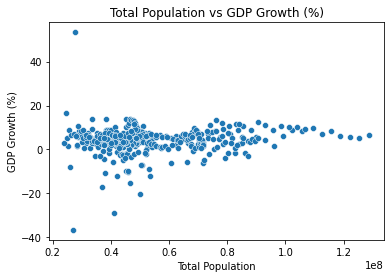

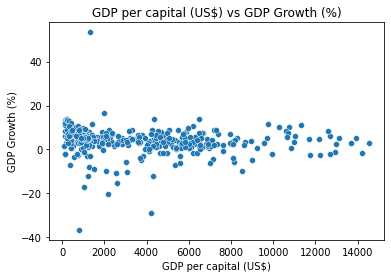

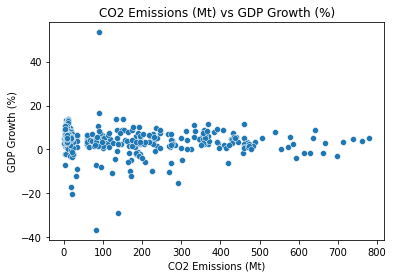

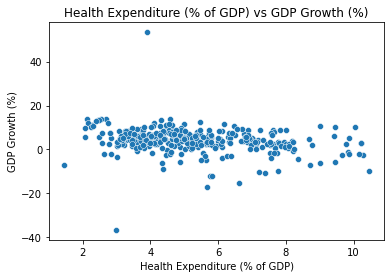

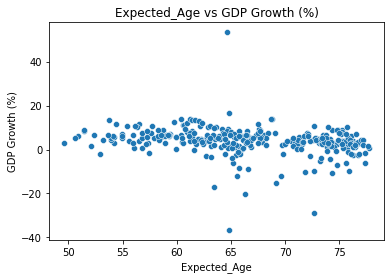

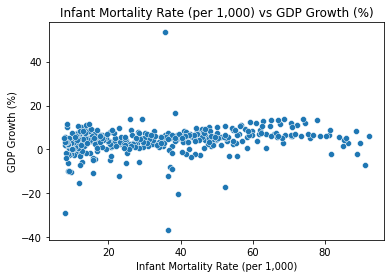

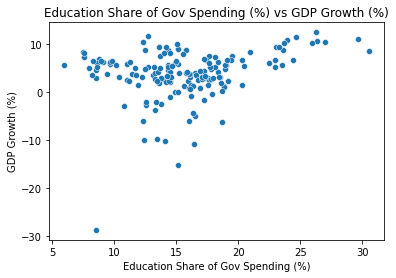

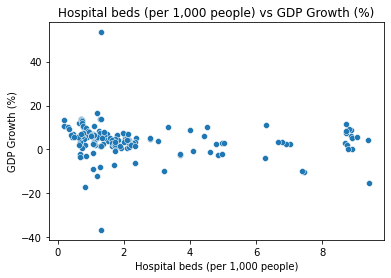

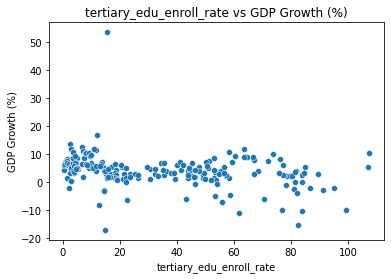

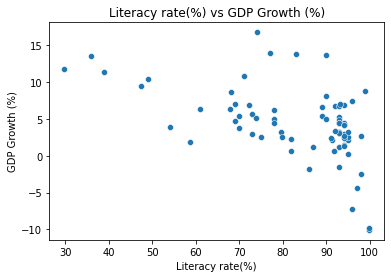

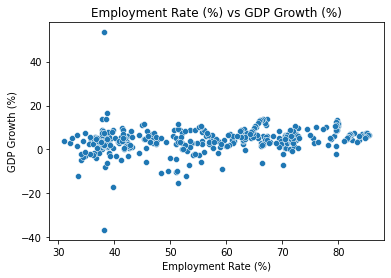

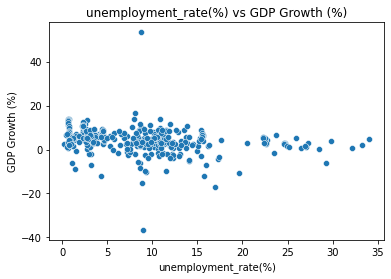

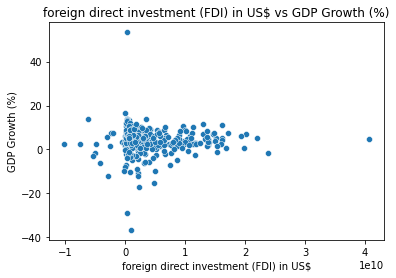

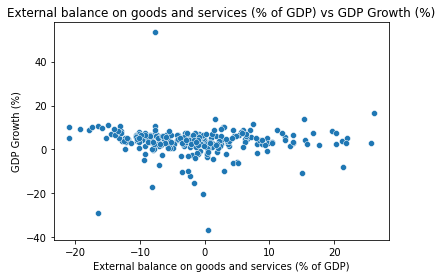

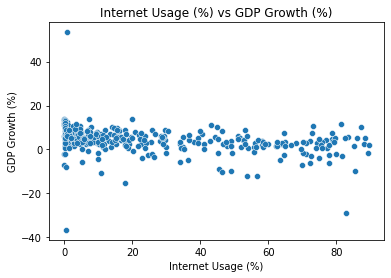

In [46]:
for indicator in key_indicators:
    if indicator != 'GDP Growth (%)':  # avoid plotting GDP Growth against itself
        sns.scatterplot(data=filtered_df, x=indicator, y='GDP Growth (%)')
        plt.title(f"{indicator} vs GDP Growth (%)")
        plt.xlabel(indicator)
        plt.ylabel('GDP Growth (%)')
        plt.show()


+ From the previous scatter plots we can see that most of the regression lines is nearly flat, which refers to that **most indicators shows weak or no linear correlation with GDP Growth (%)**. But The data points may still cluster closely around the regression line. This indicates that the variability within the data points is relatively low, and the values of the GDP growth rate will not fluctuate dramatically.
+ **Some of the social indicators like Education and health spending show slightly positive trends**, which we will explore further in subsequent analyses.

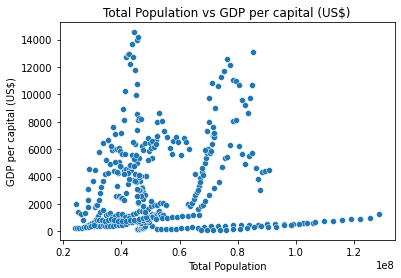

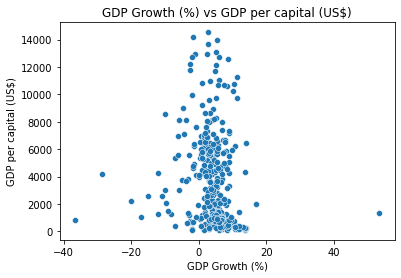

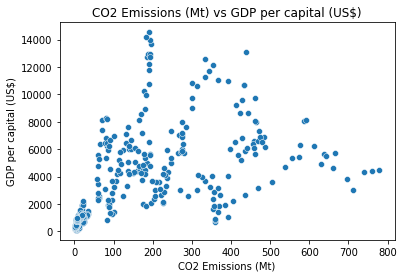

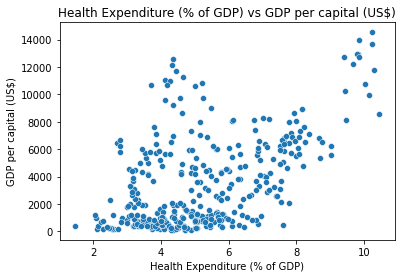

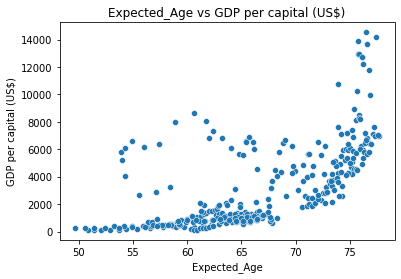

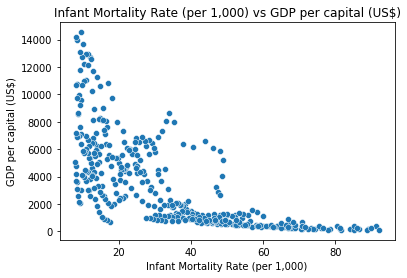

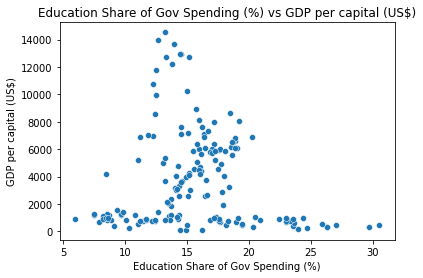

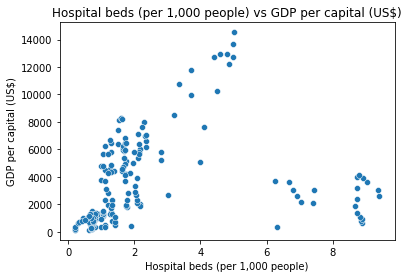

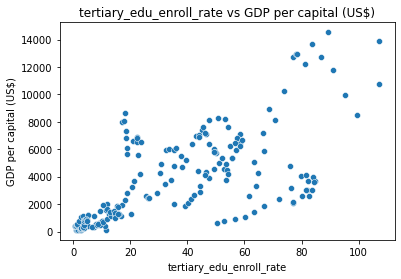

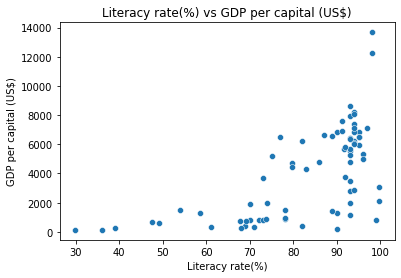

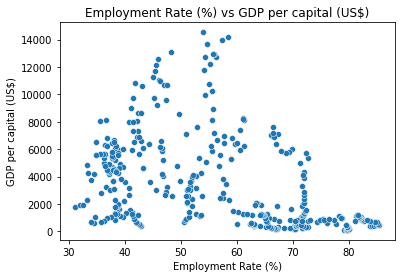

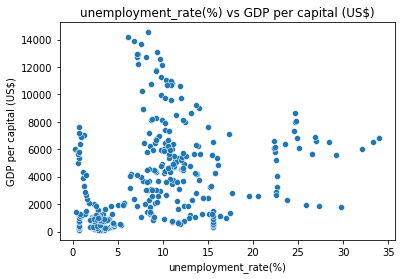

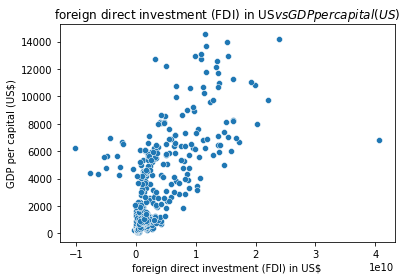

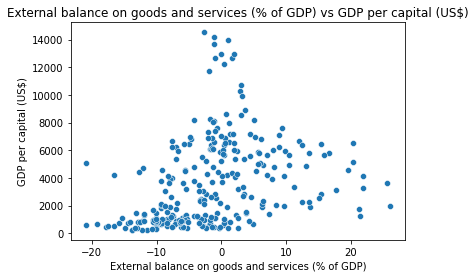

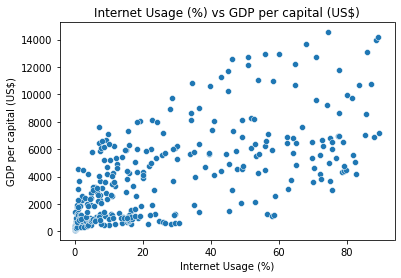

In [47]:
for indicator in key_indicators:
    if indicator != 'GDP per capital (US$)':
        sns.scatterplot(data=filtered_df, x=indicator, y='GDP per capital (US$)')
        plt.title(f"{indicator} vs GDP per capital (US$)")
        plt.xlabel(indicator)
        plt.ylabel('GDP per capital (US$)')
        plt.show()

+ From the above plots, we find that **some indicators like healthcare access, education levels, and digital infrastructure (internet usage) are positively associated with GDP per capita**. But the spread of data is wide according to the regression line, which indicates that GDP per capita might not determined by these indicators alone.
+ The most notable chart is the scatter plot of foreign direct investment (FDI), which shows an almost vertical trend. This trend indicates that **middle-income developing countries should prioritize investment in human capital in order to attract and absorb foreign direct investment**.

### Correlation matrix heatmap

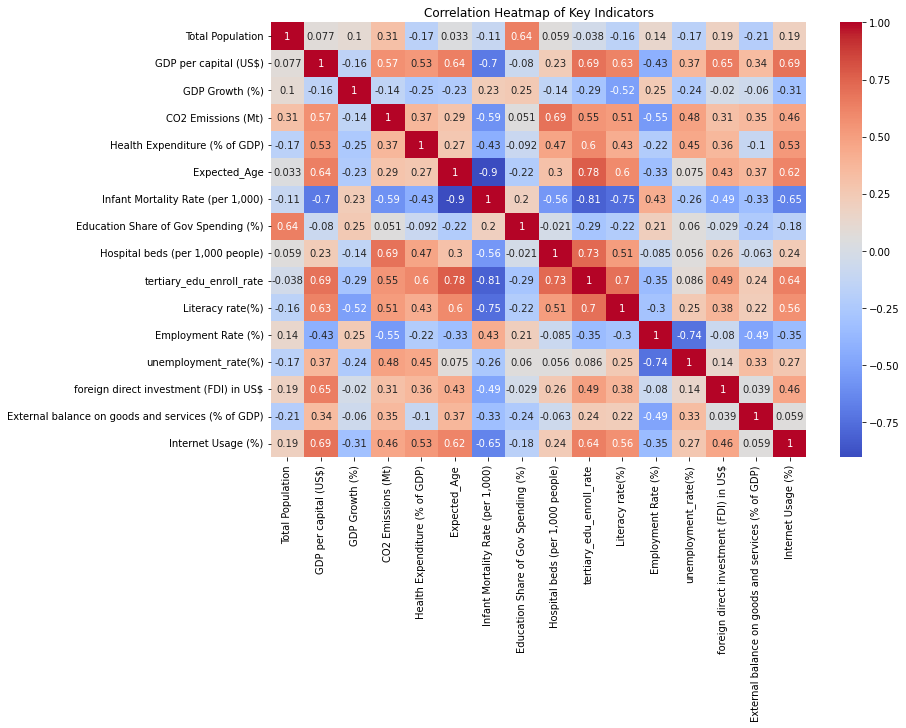

In [48]:
# Heatmap for bivariate analysis to check for the indicators' relationships
plt.figure(figsize=(12, 8))
sns.heatmap(filtered_df[key_indicators].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Key Indicators')
plt.show()

In this question, we want to focus on the analysis of the economic growth rate rather than comparing it to other countries in terms of scale.


So we gonna choose GDP_growrate as the primary reference as it is already standardized according to national scale.

From the correlation graph, we can discover that top 2 positive related indicators of GDP growth rate is Infant Mortality Rate (per 1,000) (+0.23), employmen_rate (+0.25), government educational spending(+0.25).
+ Although the Infant Mortality Rate (per 1,000) is showing a positive relationship with the GDP growth rate,it doesn't means GDP growth have a actual causal relationship with the death of infant. As the developing countires are still catching up with the infrastructure and healthcare, they are at early development stage and have more potential to growth.
+ Employment_rate and education expenditure are two of the key factor that refers the countries' economic development. Since GDP = Labor × Productivity, as more and more people are able to get work, the countries will get more economic output. Also, more spending government put in the education, more high-educated labour force the country will have.

However, a lot of indicators showed an negative relationship with the GDP growth like Internet Usage(-0.46), Literacy Rate(-0.44), Health Expenditure(-0.39), Expected Age(-0.30).
+ For Internet Usage indicator, Literacy Rate, Health Expenditure and Expected Age, these are all social infrastructure indicators that are similar to the Infant Mortality Rate. These developing countries have longer economic growth cycles and lagging infrastructure construction cycles, so their economic growth rates will outpace infrastructure construction rates during this phase. The infrastructure will gradually catch up once they reach a certain peak.

So now we gonna to conduct futher analysis based on these factors

### Economic opportunities: Employment v.s. GDP Growth

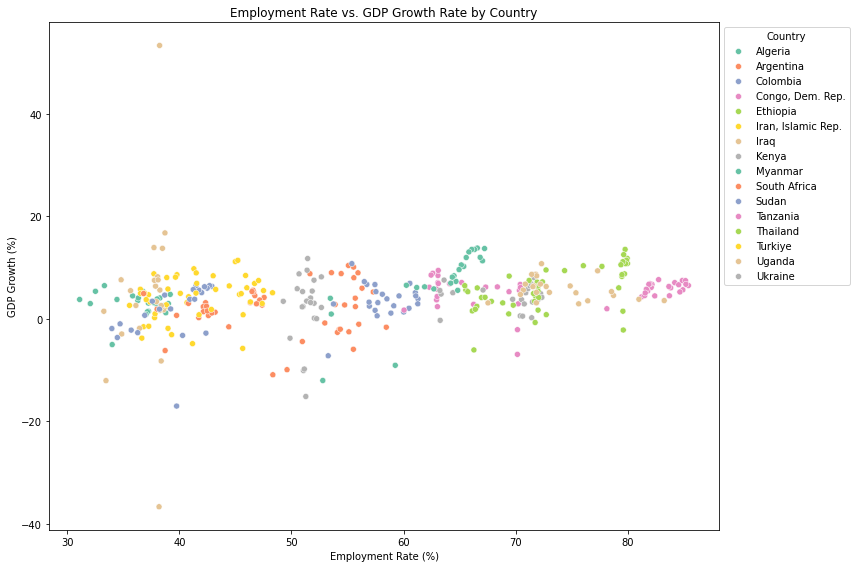

In [49]:
# as the employment rate is the major factor that can directly influence the gdp growth, we started our analysis with it.
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=filtered_df,
    x='Employment Rate (%)',
    y='GDP Growth (%)',
    hue='Country Name',
    palette='Set2'
)

plt.title('Employment Rate vs. GDP Growth Rate by Country')
plt.xlabel('Employment Rate (%)')
plt.ylabel('GDP Growth (%)')
plt.legend(title='Country', bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout()
plt.show()

+ The scatterplot confirms that there is a positive correlation between the employment rate and GDP growth rate in these developing countries.
+ then, we gonna do performance classification on the data points to better compare

### Quantile analysis using Myanmar

From the plot we can see Myanmar has a clear positive trend, so we first gonna pick it to do quantile analysis

In [50]:
Myanmar_data = filtered_df[filtered_df['Country Name'] == 'Myanmar'].copy()

In [51]:
# Key indicators for quantile analysis
main_emp_indicators = [
    'GDP Growth (%)',
    'Employment Rate (%)',
]

In [52]:
print("\n" + "="*60)
print("Myanmar QUANTILE BREAKDOWN BY INDICATOR")
print("="*60)

# Define quantiles
quantiles = filtered_df[main_emp_indicators].quantile([0.25, 0.5, 0.75])

# Choose a year for Myanmar (e.g., the most recent)
Myanmar_latest = Myanmar_data.sort_values("Year", ascending=False).iloc[0]

# Analyze where Myanmar stands for each indicator
for col in main_emp_indicators:
    value = Myanmar_latest[col]
    if pd.isna(value):
        print(f"{col}: Data missing for Myanmar.")
        continue

    q1 = quantiles.loc[0.25, col]
    q2 = quantiles.loc[0.5, col]
    q3 = quantiles.loc[0.75, col]

    if value <= q1:
        pos = "Bottom 25% (Q1−)"
    elif value <= q2:
        pos = "25%–50% (Q2−)"
    elif value <= q3:
        pos = "50%–75% (Q3−)"
    else:
        pos = "Top 25% (Q3+)"

    print(f"{col}: {value:.2f} → {pos}")



Myanmar QUANTILE BREAKDOWN BY INDICATOR
GDP Growth (%): 0.96 → Bottom 25% (Q1−)
Employment Rate (%): 53.55 → 25%–50% (Q2−)


+ This analysis of Myanmar data has proven that countries with higher employment rates tend to achieve stronger GDP growth, since both of the indicators quit low compared with other countries, especially the employment rate (below the median).  -> This suggests that strengthening labour market participation may be a necessary condition for helping countries expand their economic activities.

### Education and Health Spending Efficiency

Efficiency Analysis for education and health areas between 2005 and 2023

+ as we can discover, education shared of Gov expending(+0.03) is one of the positive corr with our GDP growth and Literacy Rate(-0.44), Health Expenditure(-0.39), Expected Age(-0.30) are two of top negative corr with the GDP growth rate.
+in order to find out the reason and discover the relationships betterwe gonna to conduct effeciency analysis.
+ since the main factors will influence these 2 area is the government expending and major outcome of the implemented policy will be reflected in the Literacy rate and expected age of the citizen. We are going to use those indicators to do calculation.

In [53]:
Effect_df_filtered = filtered_df[filtered_df['Year'].between(2005, 2023)]
Effect_df_filtered

,Country Name,Country Code,Year,Total Population,GDP per capital (US$),GDP Growth (%),CO2 Emissions (Mt),Health Expenditure (% of GDP),Expected_Age,"Infant Mortality Rate (per 1,000)","Hospital beds (per 1,000 people)",tertiary_edu_enroll_rate,Education Share of Gov Spending (%),Literacy rate(%),Employment Rate (%),unemployment_rate(%),foreign direct investment (FDI) in US$,External balance on goods and services (% of GDP),Internet Usage (%),Share of population covered by health insurance (ILO (2014))
5,Algeria,DZA,2005,33109249.0,3233.133396,5.400000,101.3970,3.118861,72.8360,29.0,NaN,20.70987,NaN,NaN,36.725,15.270,1.156000e+09,21.902105,5.84,85.2
6,Algeria,DZA,2006,33623506.0,3660.661047,2.900000,105.5010,3.189999,73.1164,27.9,1.72,21.34580,NaN,73.0,37.946,12.270,1.841000e+09,25.612976,7.38,NaN
7,Algeria,DZA,2007,34189416.0,4167.451699,3.100000,108.9121,3.620114,73.3460,26.9,NaN,23.59563,NaN,NaN,37.226,13.790,1.686737e+09,21.894838,9.45,NaN
8,Algeria,DZA,2008,34816961.0,5180.918815,2.500000,113.7024,3.983310,73.6181,25.9,1.75,NaN,11.020760,75.0,38.264,11.330,2.638607e+09,20.265871,10.20,NaN
9,Algeria,DZA,2009,35490445.0,4235.429905,1.200000,116.0855,4.892108,73.8711,25.1,1.75,30.50147,NaN,NaN,38.779,10.160,2.746931e+09,0.887258,11.20,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,Ukraine,UKR,2019,44957458.0,3619.861572,3.199504,207.8431,7.091751,73.9199,8.3,6.67,84.48136,14.558100,NaN,51.703,8.194,5.796000e+09,-8.047852,70.10,NaN
380,Ukraine,UKR,2020,44680014.0,3709.769287,-3.752818,198.6575,7.562171,73.2833,8.1,6.26,82.13460,13.273007,NaN,49.868,9.475,3.040000e+08,-1.513160,75.00,NaN
381,Ukraine,UKR,2021,44298640.0,4775.945801,3.445621,194.0549,8.202748,71.6308,8.0,NaN,75.90794,14.251876,NaN,49.266,9.834,7.954000e+09,-1.321280,79.20,NaN
382,Ukraine,UKR,2022,41048766.0,4199.670898,-28.758584,138.3356,NaN,72.6582,8.0,NaN,NaN,8.485857,NaN,NaN,NaN,2.210000e+08,-16.506283,82.70,NaN


#### Education Efficiency

In [54]:
# count the effective ratio for education from the current government expending to check if there's any improvement needed on the policy.
edu_effect_df = Effect_df_filtered.copy()
edu_effect_df['Education_Efficiency'] = edu_effect_df['Literacy rate(%)'] / edu_effect_df['Education Share of Gov Spending (%)']


In [55]:
edu_effect_df

,Country Name,Country Code,Year,Total Population,GDP per capital (US$),GDP Growth (%),CO2 Emissions (Mt),Health Expenditure (% of GDP),Expected_Age,"Infant Mortality Rate (per 1,000)",...,tertiary_edu_enroll_rate,Education Share of Gov Spending (%),Literacy rate(%),Employment Rate (%),unemployment_rate(%),foreign direct investment (FDI) in US$,External balance on goods and services (% of GDP),Internet Usage (%),Share of population covered by health insurance (ILO (2014)),Education_Efficiency
5,Algeria,DZA,2005,33109249.0,3233.133396,5.400000,101.3970,3.118861,72.8360,29.0,...,20.70987,NaN,NaN,36.725,15.270,1.156000e+09,21.902105,5.84,85.2,NaN
6,Algeria,DZA,2006,33623506.0,3660.661047,2.900000,105.5010,3.189999,73.1164,27.9,...,21.34580,NaN,73.0,37.946,12.270,1.841000e+09,25.612976,7.38,NaN,NaN
7,Algeria,DZA,2007,34189416.0,4167.451699,3.100000,108.9121,3.620114,73.3460,26.9,...,23.59563,NaN,NaN,37.226,13.790,1.686737e+09,21.894838,9.45,NaN,NaN
8,Algeria,DZA,2008,34816961.0,5180.918815,2.500000,113.7024,3.983310,73.6181,25.9,...,NaN,11.020760,75.0,38.264,11.330,2.638607e+09,20.265871,10.20,NaN,6.805338
9,Algeria,DZA,2009,35490445.0,4235.429905,1.200000,116.0855,4.892108,73.8711,25.1,...,30.50147,NaN,NaN,38.779,10.160,2.746931e+09,0.887258,11.20,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,Ukraine,UKR,2019,44957458.0,3619.861572,3.199504,207.8431,7.091751,73.9199,8.3,...,84.48136,14.558100,NaN,51.703,8.194,5.796000e+09,-8.047852,70.10,NaN,NaN
380,Ukraine,UKR,2020,44680014.0,3709.769287,-3.752818,198.6575,7.562171,73.2833,8.1,...,82.13460,13.273007,NaN,49.868,9.475,3.040000e+08,-1.513160,75.00,NaN,NaN
381,Ukraine,UKR,2021,44298640.0,4775.945801,3.445621,194.0549,8.202748,71.6308,8.0,...,75.90794,14.251876,NaN,49.266,9.834,7.954000e+09,-1.321280,79.20,NaN,NaN
382,Ukraine,UKR,2022,41048766.0,4199.670898,-28.758584,138.3356,NaN,72.6582,8.0,...,NaN,8.485857,NaN,NaN,NaN,2.210000e+08,-16.506283,82.70,NaN,NaN


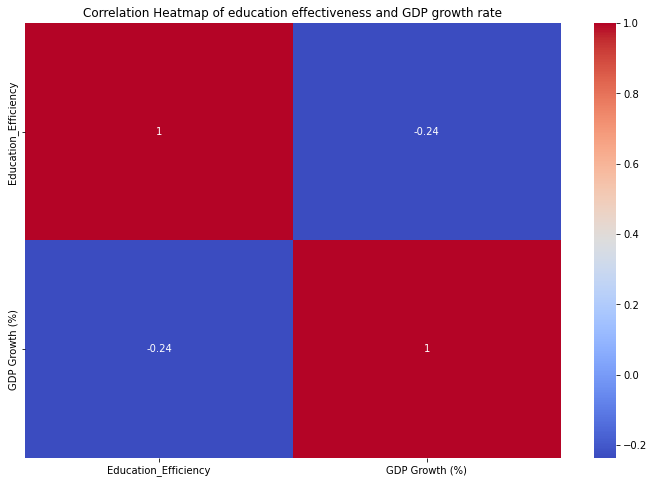

In [56]:
plt.figure(figsize=(12, 8))
sns.heatmap(edu_effect_df[['Education_Efficiency', 'GDP Growth (%)']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of education effectiveness and GDP growth rate')
plt.show()

+ This fits perfectly with our initial theory: developing countries with great potential but lacking infrastructure may invest more in education. However, due to rapid economic development and the delayed nature of education, people also need time to complete their studies, so it appears to be inefficient in the short term.

+ now, we'll still choose South Africa as the example country to analysis since it's population is very close to 60 million.


In [57]:
edu_effect_df[edu_effect_df['Country Name'] == 'South Africa'].sort_values('Year', ascending=False).iloc[0]['Total Population']

np.float64(63212384.0)

In [58]:
South_Africa_edu_df = edu_effect_df[edu_effect_df['Country Name'] == 'South Africa']
South_Africa_edu_df

,Country Name,Country Code,Year,Total Population,GDP per capital (US$),GDP Growth (%),CO2 Emissions (Mt),Health Expenditure (% of GDP),Expected_Age,"Infant Mortality Rate (per 1,000)",...,tertiary_edu_enroll_rate,Education Share of Gov Spending (%),Literacy rate(%),Employment Rate (%),unemployment_rate(%),foreign direct investment (FDI) in US$,External balance on goods and services (% of GDP),Internet Usage (%),Share of population covered by health insurance (ILO (2014)),Education_Efficiency
221,South Africa,ZAF,2005,49490033.0,5836.876633,5.277052,436.2792,6.862162,53.9142,47.9,...,NaN,18.084438,NaN,46.615,22.461,6.522098e+09,-0.228252,7.49,NaN,NaN
222,South Africa,ZAF,2006,49998277.0,6077.382934,5.603806,440.6038,6.876509,54.2204,46.0,...,NaN,19.019780,NaN,46.565,22.324,6.232917e+08,-1.571642,7.61,NaN,NaN
223,South Africa,ZAF,2007,50528584.0,6591.855360,5.360474,459.9637,6.905108,54.9477,43.8,...,NaN,NaN,89.00000,46.474,22.287,6.586792e+09,-1.207210,8.07,NaN,NaN
224,South Africa,ZAF,2008,51114599.0,6184.754743,3.191044,487.9087,7.148323,55.9817,40.6,...,NaN,18.545376,NaN,46.314,22.407,9.885001e+09,-1.465177,8.43,NaN,NaN
225,South Africa,ZAF,2009,51728516.0,6374.705600,-1.538089,456.9359,7.649415,57.4130,37.7,...,NaN,17.235180,93.00000,44.402,23.523,7.624490e+09,0.377958,10.00,NaN,5.395940
226,South Africa,ZAF,2010,52344051.0,7973.471958,3.039733,464.3343,7.793582,58.8863,35.4,...,17.127625,17.234957,93.00000,40.800,24.683,3.693272e+09,1.160748,24.00,100.0,5.396010
227,South Africa,ZAF,2011,52995205.0,8646.055711,3.168556,444.6378,7.944344,60.6024,33.9,...,18.328827,18.456661,93.00000,42.330,24.639,4.139289e+09,0.759946,34.00,NaN,5.038831
228,South Africa,ZAF,2012,53782567.0,8076.976785,2.396232,460.8901,8.004289,61.7366,33.0,...,17.944720,19.202827,94.00000,42.122,24.727,4.626029e+09,-1.304319,41.00,NaN,4.895113
229,South Africa,ZAF,2013,54678791.0,7331.654674,2.485468,472.7454,8.103223,62.3883,32.0,...,18.608820,16.750700,NaN,42.411,24.561,8.232519e+09,-2.116467,46.50,NaN,NaN
230,South Africa,ZAF,2014,55594838.0,6856.731371,1.413826,484.0482,7.871366,63.1845,30.9,...,18.481340,16.351250,94.00000,42.131,24.890,5.791659e+09,-1.498336,49.00,NaN,5.748796


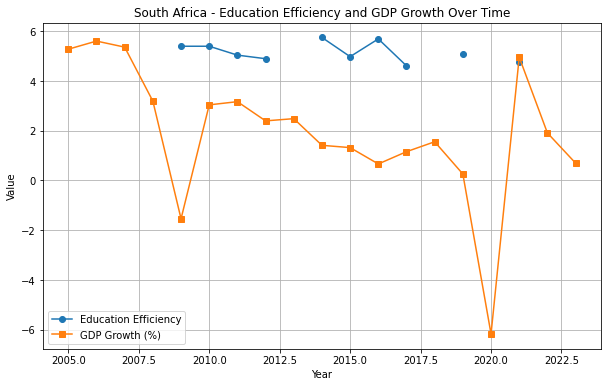

In [59]:
plt.figure(figsize=(10, 6))

plt.plot(South_Africa_edu_df['Year'], South_Africa_edu_df['Education_Efficiency'], label='Education Efficiency', marker='o')

plt.plot(South_Africa_edu_df['Year'], South_Africa_edu_df['GDP Growth (%)'], label='GDP Growth (%)', marker='s')

plt.xlabel('Year')
plt.ylabel('Value')
plt.title('South Africa - Education Efficiency and GDP Growth Over Time')
plt.legend()
plt.grid(True)
plt.show()

+ Educational efficiency (literacy rate/education expenditure) remained relatively stable, with only slight fluctuations, while GDP growth rate showed significant fluctuations again. -> This indicates that the relationship between the two is very weak.

#### Health Effeciency

In [60]:
# now wo do the analysis to health area
health_effect_df = Effect_df_filtered.copy()
health_effect_df['Health_Efficiency'] = health_effect_df['Expected_Age'] / health_effect_df['Health Expenditure (% of GDP)']

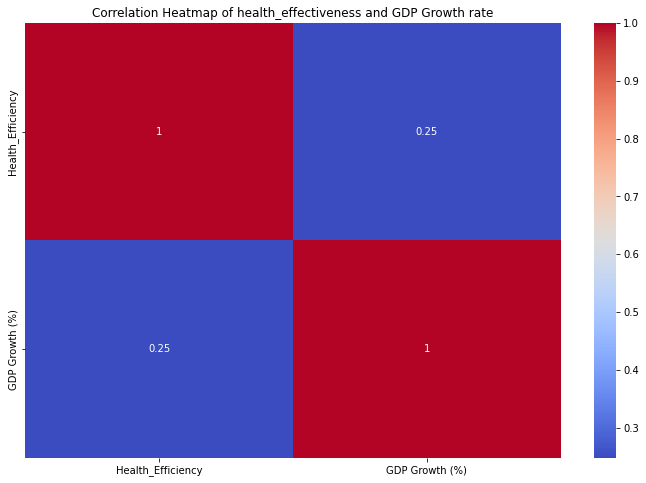

In [61]:
plt.figure(figsize=(12, 8))
sns.heatmap(health_effect_df[['Health_Efficiency', 'GDP Growth (%)']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of health_effectiveness and GDP Growth rate')
plt.show()

+ The correlation coefficient is +0.25, indicating a weak positive correlation between health efficiency and GDP growth, which suggests the possibility that improvements in health status may not be driven by GDP.

In [62]:
South_Africa_health_df = health_effect_df[health_effect_df['Country Name'] == 'South Africa']
South_Africa_health_df

,Country Name,Country Code,Year,Total Population,GDP per capital (US$),GDP Growth (%),CO2 Emissions (Mt),Health Expenditure (% of GDP),Expected_Age,"Infant Mortality Rate (per 1,000)",...,tertiary_edu_enroll_rate,Education Share of Gov Spending (%),Literacy rate(%),Employment Rate (%),unemployment_rate(%),foreign direct investment (FDI) in US$,External balance on goods and services (% of GDP),Internet Usage (%),Share of population covered by health insurance (ILO (2014)),Health_Efficiency
221,South Africa,ZAF,2005,49490033.0,5836.876633,5.277052,436.2792,6.862162,53.9142,47.9,...,NaN,18.084438,NaN,46.615,22.461,6.522098e+09,-0.228252,7.49,NaN,7.856737
222,South Africa,ZAF,2006,49998277.0,6077.382934,5.603806,440.6038,6.876509,54.2204,46.0,...,NaN,19.019780,NaN,46.565,22.324,6.232917e+08,-1.571642,7.61,NaN,7.884873
223,South Africa,ZAF,2007,50528584.0,6591.855360,5.360474,459.9637,6.905108,54.9477,43.8,...,NaN,NaN,89.00000,46.474,22.287,6.586792e+09,-1.207210,8.07,NaN,7.957543
224,South Africa,ZAF,2008,51114599.0,6184.754743,3.191044,487.9087,7.148323,55.9817,40.6,...,NaN,18.545376,NaN,46.314,22.407,9.885001e+09,-1.465177,8.43,NaN,7.831446
225,South Africa,ZAF,2009,51728516.0,6374.705600,-1.538089,456.9359,7.649415,57.4130,37.7,...,NaN,17.235180,93.00000,44.402,23.523,7.624490e+09,0.377958,10.00,NaN,7.505542
226,South Africa,ZAF,2010,52344051.0,7973.471958,3.039733,464.3343,7.793582,58.8863,35.4,...,17.127625,17.234957,93.00000,40.800,24.683,3.693272e+09,1.160748,24.00,100.0,7.555742
227,South Africa,ZAF,2011,52995205.0,8646.055711,3.168556,444.6378,7.944344,60.6024,33.9,...,18.328827,18.456661,93.00000,42.330,24.639,4.139289e+09,0.759946,34.00,NaN,7.628371
228,South Africa,ZAF,2012,53782567.0,8076.976785,2.396232,460.8901,8.004289,61.7366,33.0,...,17.944720,19.202827,94.00000,42.122,24.727,4.626029e+09,-1.304319,41.00,NaN,7.712940
229,South Africa,ZAF,2013,54678791.0,7331.654674,2.485468,472.7454,8.103223,62.3883,32.0,...,18.608820,16.750700,NaN,42.411,24.561,8.232519e+09,-2.116467,46.50,NaN,7.699196
230,South Africa,ZAF,2014,55594838.0,6856.731371,1.413826,484.0482,7.871366,63.1845,30.9,...,18.481340,16.351250,94.00000,42.131,24.890,5.791659e+09,-1.498336,49.00,NaN,8.027133


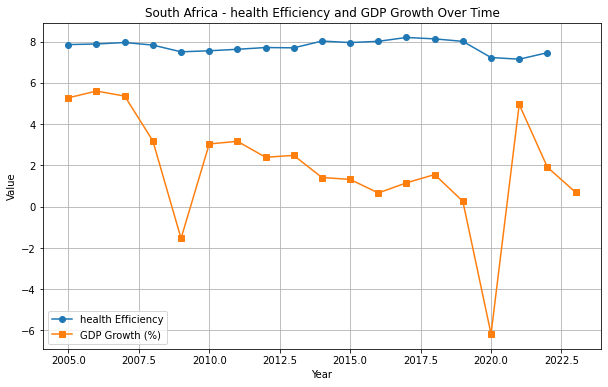

In [63]:
plt.figure(figsize=(10, 6))

plt.plot(South_Africa_health_df['Year'], South_Africa_health_df['Health_Efficiency'], label='health Efficiency', marker='o')

plt.plot(South_Africa_health_df['Year'], South_Africa_health_df['GDP Growth (%)'], label='GDP Growth (%)', marker='s')

plt.xlabel('Year')
plt.ylabel('Value')
plt.title('South Africa - health Efficiency and GDP Growth Over Time')
plt.legend()
plt.grid(True)
plt.show()

+ from the graph we can see that the health efficiency (based on life expectancy/health expenditure percentage) remained relatively stable and at a high level between 2005 and 2022.
+ However, between 2020 and 2023, we can see that South Africa's healthcare efficiency and economic development have experienced similar fluctuations, possibly due to the impact of COVID-19.

## GDP and Emission

Evaluate the potential impact of your recommended GDP improvement strategies on carbon emissions in the country. Are there significant trade–offs or challenges associated with balancing GDP improvement and carbon emissions?

In [64]:
CO2_gdp_df = filtered_df.copy()
CO2_gdp_df

,Country Name,Country Code,Year,Total Population,GDP per capital (US$),GDP Growth (%),CO2 Emissions (Mt),Health Expenditure (% of GDP),Expected_Age,"Infant Mortality Rate (per 1,000)","Hospital beds (per 1,000 people)",tertiary_edu_enroll_rate,Education Share of Gov Spending (%),Literacy rate(%),Employment Rate (%),unemployment_rate(%),foreign direct investment (FDI) in US$,External balance on goods and services (% of GDP),Internet Usage (%),Share of population covered by health insurance (ILO (2014))
0,Algeria,DZA,2000,30903893.0,1772.928691,3.800000,87.9362,3.214854,70.5759,34.7,1.77,NaN,NaN,NaN,31.088,29.770,2.801000e+08,21.281092,0.492,NaN
1,Algeria,DZA,2001,31331221.0,1896.300209,3.000000,85.8203,3.536286,71.0245,33.6,1.76,15.29478,NaN,NaN,32.037,27.300,1.113106e+09,13.712813,0.646,NaN
2,Algeria,DZA,2002,31750835.0,1937.464114,5.400000,89.6841,3.441696,71.6437,32.4,1.75,16.97542,NaN,70.0,32.499,25.900,1.064960e+09,9.684723,1.590,NaN
3,Algeria,DZA,2003,32175818.0,2283.772993,6.500000,96.5024,3.325694,71.9064,31.3,1.78,18.21182,NaN,NaN,33.299,23.720,6.378530e+08,13.568992,2.200,NaN
4,Algeria,DZA,2004,32628286.0,2816.993850,4.500000,96.6218,3.290305,72.5359,30.1,1.81,18.87093,NaN,NaN,35.818,17.650,8.847490e+08,15.427921,4.630,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,Ukraine,UKR,2019,44957458.0,3619.861572,3.199504,207.8431,7.091751,73.9199,8.3,6.67,84.48136,14.558100,NaN,51.703,8.194,5.796000e+09,-8.047852,70.100,NaN
380,Ukraine,UKR,2020,44680014.0,3709.769287,-3.752818,198.6575,7.562171,73.2833,8.1,6.26,82.13460,13.273007,NaN,49.868,9.475,3.040000e+08,-1.513160,75.000,NaN
381,Ukraine,UKR,2021,44298640.0,4775.945801,3.445621,194.0549,8.202748,71.6308,8.0,NaN,75.90794,14.251876,NaN,49.266,9.834,7.954000e+09,-1.321280,79.200,NaN
382,Ukraine,UKR,2022,41048766.0,4199.670898,-28.758584,138.3356,NaN,72.6582,8.0,NaN,NaN,8.485857,NaN,NaN,NaN,2.210000e+08,-16.506283,82.700,NaN


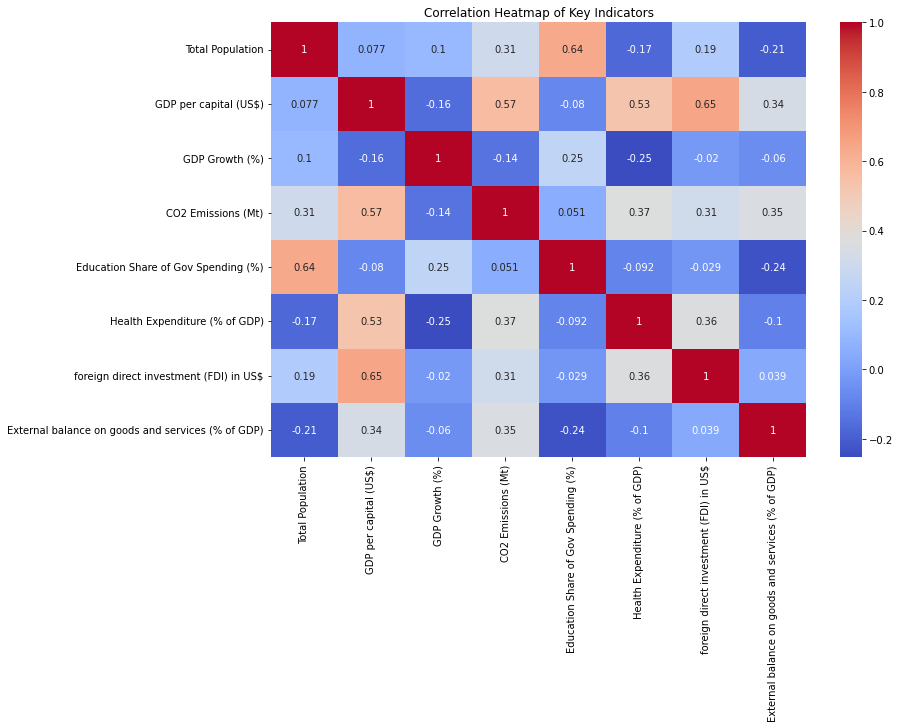

In [65]:
plt.figure(figsize=(12, 8))
developemt_related_indicators = ['Total Population', 'GDP per capital (US$)', 'GDP Growth (%)', 'CO2 Emissions (Mt)','Education Share of Gov Spending (%)',
                 'Health Expenditure (% of GDP)', 'foreign direct investment (FDI) in US$','External balance on goods and services (% of GDP)']
sns.heatmap(CO2_gdp_df[developemt_related_indicators].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Key Indicators')
plt.show()

+ As we can see from the correlation graph, CO2 emission is highly correlated with the External balance on goods, services and GDP per capita, and the indicators that
related with growth of the population and country development.
+ Then, we gonna to plot out the GDP per capita and CO2 emission data to see if there's any obvious trend.

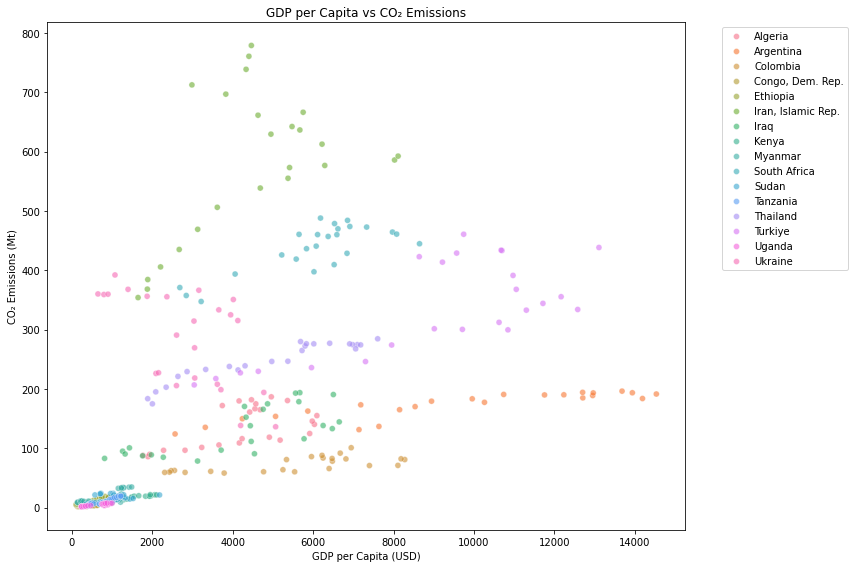

In [66]:
# Then, we plot the data that related to co2 emission and GDP per capita
plt.figure(figsize=(12, 8))
sns.scatterplot(data=CO2_gdp_df, x='GDP per capital (US$)', y='CO2 Emissions (Mt)', hue='Country Name', alpha=0.6)
plt.title('GDP per Capita vs CO₂ Emissions')
plt.xlabel('GDP per Capita (USD)')
plt.ylabel('CO₂ Emissions (Mt)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.show()


### Kuznets Curve

The Environmental Kuznets Curve (EKC) is a hypothesis that posits an inverted U-shaped relationship between environmental degradation and GDP per capita. As a country develops, pollution initially increases due to scale effects and structural effects. So based on this hypothesis, we gonna prove the trend with our data.
+ from above we can see GDP Growth vs CO2 Emissions correlation = -0.258, which is weak negative

#### South Africa example

We choose South Africa to do our example analysis as it has an obvious trend from the previous plot.

Fit with a  quadratic Regression. We choose 2nd Degree Polynomial as the EKC hypothesis suggests that as GDP per capita increases, environmental degradation (like CO2 emissions) will follow a U shape, which first increases and then decreases.

In [67]:
# Filter South Africa data
sa_co2_df = CO2_gdp_df[CO2_gdp_df['Country Name'] == 'South Africa']

# Prepare variables
x = sa_co2_df['GDP per capital (US$)']
y = sa_co2_df['CO2 Emissions (Mt)']

# Fit 2nd-degree polynomial (Kuznets Curve)
coeffs = np.polyfit(x, y, 2)
poly_eq = np.poly1d(coeffs)
x_sorted = np.sort(x)
y_fit = poly_eq(x_sorted)


In [68]:
# Calculate turning point: x = -b / (2a)
turning_x = -coeffs[1] / (2 * coeffs[0])
turning_y = poly_eq(turning_x)

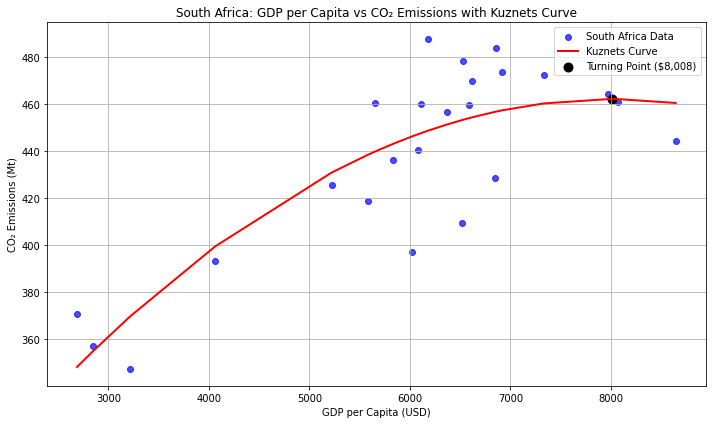

In [69]:
# Plot
plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='blue', label='South Africa Data', alpha=0.7)

# Plot Kuznets curve
plt.plot(x_sorted, y_fit, color='red', linewidth=2, label='Kuznets Curve')

# Mark turning point
plt.scatter(turning_x, turning_y, color='black', s=80, marker='o', label=f'Turning Point (${turning_x:,.0f})')

plt.xlabel('GDP per Capita (USD)')
plt.ylabel('CO₂ Emissions (Mt)')
plt.title('South Africa: GDP per Capita vs CO₂ Emissions with Kuznets Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


South Africa's curve almost perfectly aligns with the Environmental Kuznets Curve (EKC) hypothesis. This indicates that **carbon dioxide emissions rise with increases in GDP per capita until reaching a turning point** (at approximately $8,000 for South Africa), after which they begin to stabilize or slightly decline.

In order to compare, we gonna also plot Thailand to see the trend

In [70]:
th_df = CO2_gdp_df[CO2_gdp_df['Country Name'] == 'Thailand']

In [71]:
x = th_df['GDP per capital (US$)']
y = th_df['CO2 Emissions (Mt)']

#Fit 2nd-degree polynomial (Kuznets)
coeffs = np.polyfit(x, y, 2)
poly_eq = np.poly1d(coeffs)
x_sorted = np.sort(x)
y_fit = poly_eq(x_sorted)

turning_x = -coeffs[1] / (2 * coeffs[0])
turning_y = poly_eq(turning_x)

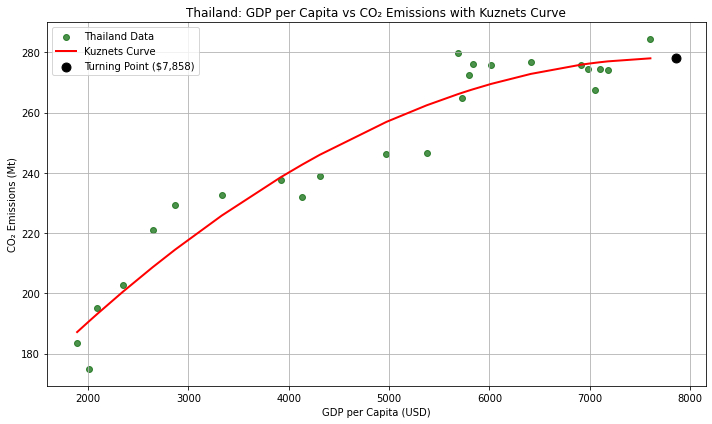

In [72]:
#plot
plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='darkgreen', label='Thailand Data', alpha=0.7)
plt.plot(x_sorted, y_fit, color='red', linewidth=2, label='Kuznets Curve')
plt.scatter(turning_x, turning_y, color='black', s=80, marker='o', label=f'Turning Point (${turning_x:,.0f})')
plt.xlabel('GDP per Capita (USD)')
plt.ylabel('CO₂ Emissions (Mt)')
plt.title('Thailand: GDP per Capita vs CO₂ Emissions with Kuznets Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### Thailand example

 Similarly, Thailand's emissions curve continues to rise steeply, suggesting that the country is still in the ascending phase of the EKC but will soon reach the turning point (GDP per capita of $7,858). However, its overall trend is also highly consistent with the Environmental Kuznets Curve (EKC) hypothesis.

## GDP and Health Policies

The country’s president has indicated he believes that the country doesn’t need to focus on its health policies, as increasing GDP should improve health outcomes. Analyze the data on the relationship between a country’s wealth and health outcomes. To what extent does an increase in national wealth correlate with improved health outcomes? Are the President’s claims supported by the data?

In [73]:
health_gdp_df = filtered_df.copy()
health_gdp_df

,Country Name,Country Code,Year,Total Population,GDP per capital (US$),GDP Growth (%),CO2 Emissions (Mt),Health Expenditure (% of GDP),Expected_Age,"Infant Mortality Rate (per 1,000)","Hospital beds (per 1,000 people)",tertiary_edu_enroll_rate,Education Share of Gov Spending (%),Literacy rate(%),Employment Rate (%),unemployment_rate(%),foreign direct investment (FDI) in US$,External balance on goods and services (% of GDP),Internet Usage (%),Share of population covered by health insurance (ILO (2014))
0,Algeria,DZA,2000,30903893.0,1772.928691,3.800000,87.9362,3.214854,70.5759,34.7,1.77,NaN,NaN,NaN,31.088,29.770,2.801000e+08,21.281092,0.492,NaN
1,Algeria,DZA,2001,31331221.0,1896.300209,3.000000,85.8203,3.536286,71.0245,33.6,1.76,15.29478,NaN,NaN,32.037,27.300,1.113106e+09,13.712813,0.646,NaN
2,Algeria,DZA,2002,31750835.0,1937.464114,5.400000,89.6841,3.441696,71.6437,32.4,1.75,16.97542,NaN,70.0,32.499,25.900,1.064960e+09,9.684723,1.590,NaN
3,Algeria,DZA,2003,32175818.0,2283.772993,6.500000,96.5024,3.325694,71.9064,31.3,1.78,18.21182,NaN,NaN,33.299,23.720,6.378530e+08,13.568992,2.200,NaN
4,Algeria,DZA,2004,32628286.0,2816.993850,4.500000,96.6218,3.290305,72.5359,30.1,1.81,18.87093,NaN,NaN,35.818,17.650,8.847490e+08,15.427921,4.630,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,Ukraine,UKR,2019,44957458.0,3619.861572,3.199504,207.8431,7.091751,73.9199,8.3,6.67,84.48136,14.558100,NaN,51.703,8.194,5.796000e+09,-8.047852,70.100,NaN
380,Ukraine,UKR,2020,44680014.0,3709.769287,-3.752818,198.6575,7.562171,73.2833,8.1,6.26,82.13460,13.273007,NaN,49.868,9.475,3.040000e+08,-1.513160,75.000,NaN
381,Ukraine,UKR,2021,44298640.0,4775.945801,3.445621,194.0549,8.202748,71.6308,8.0,NaN,75.90794,14.251876,NaN,49.266,9.834,7.954000e+09,-1.321280,79.200,NaN
382,Ukraine,UKR,2022,41048766.0,4199.670898,-28.758584,138.3356,NaN,72.6582,8.0,NaN,NaN,8.485857,NaN,NaN,NaN,2.210000e+08,-16.506283,82.700,NaN


In [74]:
health_related_indicators = [
    'Total Population',
    'GDP per capital (US$)',
    'GDP Growth (%)',
    'Health Expenditure (% of GDP)',
    'Expected_Age',
    'Infant Mortality Rate (per 1,000)',
    'Hospital beds (per 1,000 people)'
]

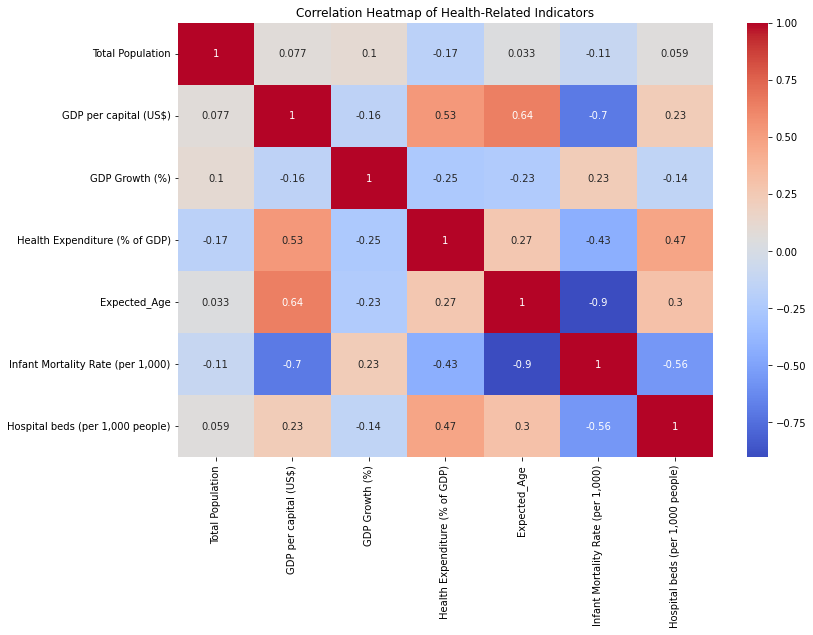

In [75]:
plt.figure(figsize=(12, 8))
sns.heatmap(health_gdp_df[health_related_indicators].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap of Health-Related Indicators")
plt.show()


+ The heat map shows that there is a negative correlation between GDP growth and life expectancy, contrary to the president's statement.
+ then, we plot all data points to see the distribution trend.

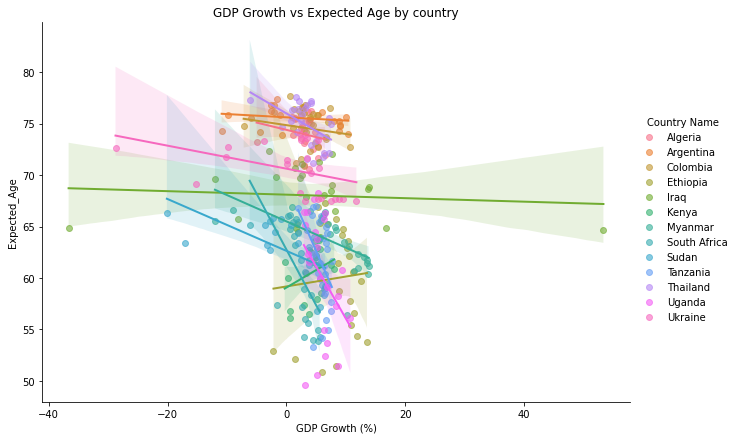

In [76]:
# Filter valid data for all years, all countries -> to see overall trend
health_age_reg = health_gdp_df.dropna(subset=['Expected_Age', 'GDP Growth (%)', 'Country Name'])

# Plot regression lines for each country
sns.lmplot(
    data=health_age_reg,
    x='GDP Growth (%)',
    y='Expected_Age',
    hue='Country Name',
    aspect=1.5,
    height=6,
    markers='o',
    scatter_kws={'alpha': 0.6},
    line_kws={'linewidth': 2}
)

plt.title('GDP Growth vs Expected Age by country')
plt.show()

Based on the above plot, we can see that most of the countries show an negative relationship between GDP growth and expected_age of the citizen.

So next, we gonna do a futher analysis on Myanmar, South Aferica, Sudan since they have a sharp slop on the regression line.

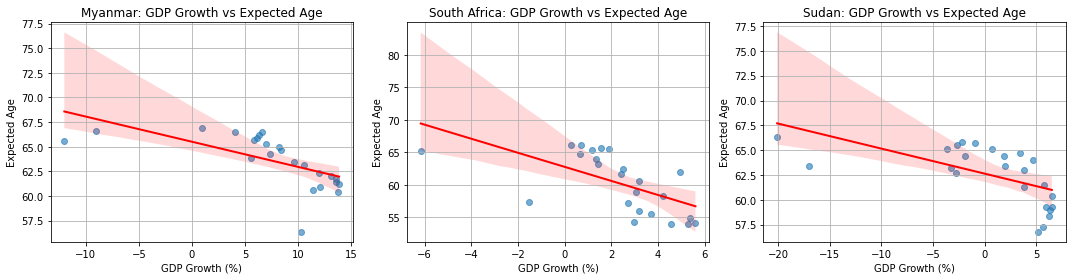

In [77]:
# List of focus countries
focus_countries = ['Myanmar', 'South Africa', 'Sudan']

# plotting
plt.figure(figsize=(15, 4))

for i, country in enumerate(focus_countries, 1):
    plt.subplot(1, 3, i)
    country_df = health_gdp_df[health_gdp_df['Country Name'] == country]

    sns.regplot(
        data=country_df,
        x='GDP Growth (%)',
        y='Expected_Age',
        scatter_kws={'alpha': 0.6},
        line_kws={'color': 'red', 'linewidth': 2}
    )

    plt.title(f'{country}: GDP Growth vs Expected Age')
    plt.xlabel('GDP Growth (%)')
    plt.ylabel('Expected Age')
    plt.grid(True)

plt.tight_layout()
plt.show()

These three figures show a strong negative correlation between GDP growth and life expectancy, the most important health indicator. This confirms that the higher the GDP growth rate, the lower the life expectancy.Especially for Myanmar, the spread of data points are very close to the regression line, which indicates that there is a consistent inverse relationship.

Therefore, we can conclude that the president's statement is not supported by the data, which shows the opposite of what he said. When society develops rapidly, the distribution of social resources becomes unfair, which may lead to poor health outcomes due to factors such as insufficient public health investment and a shortage of hospital beds.